# <a id='toc1_'></a>[Regularização L1 e L2: escolhendo uma solução entre dados redundantes](#toc0_)

Autor: Vinícius Marianno de Marque Cutolo

RM: 2610042

Professor: Daniel Roberto Cassar

**Sumário**<a id='toc0_'></a>    
- [Regularização L1 e L2: escolhendo uma solução entre dados redundantes](#toc1_)    
    - [Introdução](#toc1_1_1_)    
    - [Regressão Linear simples](#toc1_1_2_)    
    - [Evidenciação do problema](#toc1_1_3_)    
      - [Sistemas mal-condicionados](#toc1_1_3_1_)    
      - [Sistemas sub-determinados](#toc1_1_3_2_)    
    - [L2: penalização nos pesos](#toc1_1_4_)    
    - [L1: regularização geométrica](#toc1_1_5_)    
    - [Exemplos teóricos](#toc1_1_6_)    
      - [Valor de casas em terrenos](#toc1_1_6_1_)    
      - [Sistema Linear possível e indeterminado](#toc1_1_6_2_)    
    - [Exemplo prático - EEG para prever tendência de movimento](#toc1_1_7_)    
      - [Pegando os dados do Dataset](#toc1_1_7_1_)    
      - [Tratando o EEG](#toc1_1_7_2_)    
      - [Separação de dados em treino e teste](#toc1_1_7_3_)    
      - [Modelos preditivos](#toc1_1_7_4_)    
    - [Apêndice](#toc1_1_8_)    
    - [Referências](#toc1_1_9_)    

<!-- vscode-jupyter-toc-config
	numbering=false
	anchor=true
	flat=false
	minLevel=1
	maxLevel=6
	/vscode-jupyter-toc-config -->
<!-- THIS CELL WILL BE REPLACED ON TOC UPDATE. DO NOT WRITE YOUR TEXT IN THIS CELL -->

### <a id='toc1_1_1_'></a>[Introdução](#toc0_)


Imagine uma regressão linear $\hat{y}=Xw$ e uma função de erro quadrático $J(w)=||y-Xw||_2^2$. Treinar um modelo significa minimizar $J(w)$ e achar o $w$ que melhor explica o problema, porém, nos deparamos com um grande problema.

Imagine que os termos de $X$ não sejam independente, existe uma correlação entre eles e alguns são até redundantes. Isso ocorre principalmente quando há correlação forte entre os atributos ou uma quantidade muito maior de atributos do que exemplos, chamados de sistemas mal-condicionados (quando há uma correlação muito forte entre os termos) e sub-determinados (quando há muito mais atributos do que exemplos). 

Ambas as condições são definidas de forma simplificada, mal-condicionamento tem relação com a colinearidade das colunas da matriz de teste (algumas colunas podem ser aproximadas como combinações lineares das outra). Enquanto isso, sub-determinação nao só sobre disparidade entre atributos e exemplos, seria sobre a diferença entre exemplos linearmente independentes e incógnitas no nosso sistema. Com isso explicado, vamos nos referir a forma simplificada das condições daqui para frente, com o objetivo de tornar essa jornada mais didática.

Para aprofundar esses problemas, algumas células de código foram criadas para mostrar, graficamente, como que esse problema existe. 

Como exemplo de cada caso, situações simples serão usadas para nos aprofundarmos na solução por L1 e L2. Para o caso mal-condicionado, iremos tentar prever o valor de uma casa usando a área em pés quadrados e em metros quadrados. Para o caso sub-determinado, continuaremos na algebra linear: prever o resultado de três parâmetros tendo somente duas equações que os correlacione. Cada qual será desenvolvido mais em suas respectivas sessões.

Enfim, para testar a aplicabilidade dessa técnica, trataremos de um exemplo pratico a ser resolvido: interpretação de leitura de eletroencefalograma (EEG) para previsão de velocidade do punho. Esse problema é interessante pois os canais são fortemente correlacionados espacialmente, mal-condicionado, e há exemplos muito ruidosos. Ademais, existe muita redundância de informações dentro do sistema, podendo ser ou nao ser um caso de sub-determinação, mas não podemos garantir isso. Com isso, chegamos à pergunta motivadora:

*Dado que existem vários w's que explicam igualmente, ou quase igualmente, bem o problema, qual devemos escolher?*

Claro, a resposta poderia ser simplesmente 'aquele que diminua o erro', mas a regularização adiciona uma outra preferência. Ao invés de reduzir $J(w)$, a regularização L1 e L2 preza por reduzir (1).

$$
(1)\qquad J(w)+\lambda R(w) \qquad 
$$
<a id='toc0_'></a>[[1]](#toceq_1_) [[3]](#toceq_3_)

em que:

1. $J(w)$ ajusta os dados
2. $R(w)$ penaliza os parâmetros
3. $\lambda$ representa o compromisso entre o ajuste dos dados e a regularização de $R(w)$

Aos que ainda não estão familiarizados com a formula, aguarde até a próxima sessão [Regressão Linear simples](#toc1_1_2_) que isso será melhor explicado. Aviso de antemão que o leitor deve ter um conhecimento mínimo de algebra linear para entender algumas das discussões, em especial, a noção que sistemas lineares podem ser escritos na forma matricial $X\omega = \hat{y}$. Com $X$ sendo a tabela de dados, $\omega$ sendo o vetor de pesos da resposta e $\hat{y}$ o vetor resposta.

Uma das maiores utilidades dessa técnica é evitar algo denominado de overfitting,que é um fenômeno que ocorre quando um modelo se ajusta muito aos dados fornecidos e não consegue generalizar para outros <a id='toc0_'></a>[[2]](#toceq_2_). Isso ocorre porque a regularização permite mudar a preferencia estrutural do problema <a id='toc0_'></a>[[3]](#toceq_3_), que impedem uma supervalorização da interpolação pura. Contudo, a regularização L1 e L2 não está restrita a ser somente uma técnica para evitar overfitting, a sua aplicação gera um restrição do próprio espaço de soluções, sendo ótimo para forçar condições de contorno na estrutura da solução.

A seguir, o notebook irá seguir a seguinte forma:

Regressão Linear $\rightarrow$ Evidenciação do problema $\rightarrow$ L2 $\rightarrow$ L1  $\rightarrow$ exemplos teóricos $\rightarrow$ exemplo prático


In [ ]:
# Bibliotecas que serão usadas no projeto
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.io import loadmat
from scipy.signal import butter, resample_poly, savgol_filter, sosfilt, sosfilt_zi
from sklearn.linear_model import (
    Lasso,
    LassoCV,
    LinearRegression,
    MultiTaskLassoCV,
    Ridge,
    RidgeCV,
)
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import (
    GroupKFold,
    GroupShuffleSplit,
    cross_val_score,
    train_test_split,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler  # type: ignore

# RNG padrão para reprodutibilidade
rng = np.random.default_rng(42)


---
### <a id='toc1_1_2_'></a>[Regressão Linear simples](#toc0_)


Imagine a seguinte situação, você tem um conjunto de dados distribuídos de tal forma que haja uma certa tendência linear entre eles. Porém, o grande problema: não existe uma reta específica que consiga passar por todos os pontos.

Queremos um modelo capaz de se ajustar aos dados que temos com uma boa precisão, mas como escolher a reta ideal que melhor explique essa distribuição de dados? Para começarmos, imagine que estamos usando a seguinte reta para modelar o nosso problema <a id='toc0_'></a>[[1]](#toceq_1_):

$$\hat{y} = b+ \omega x$$

Em que:

1. $\hat{y}$ é o valor previsto pelo nosso modelo.

2. $b$ é o coeficiente linear da reta, chamado também de valor basal da reta.

3. $\omega$ é o coeficiente angular da reta.

4. $x$ variável de entrada

5. $y$ é o valor real da previsão

Para podermos chamar essa reta de boa, sabemos que $\hat{y}$ tem que se aproximar o máximo de $y$ para cada $x$ testado. Uma forma de mensurarmos isso é avaliar o resíduo deixado por cada previsão, denotado por $e_i=y-\hat{y}_i$. Cada resíduo irá dizer o quanto o modelo errou naquela previsão, agora basta somar todos e minimizar o resíduo, né? Um problema logo surge, podem existir componentes negativas nessa soma, o que artificialmente reduziriam o resíduo resultante mesmo o modelo não sendo bom. Para resolver isso, diversas formas foram desenvolvidas, mas duas são mais reconhecidas nesse assunto: podemos tirar o módulo de todos os termos ou elevar termo a termo ao quadrado. 

Ambos são válidos, mas nesse notebook usaremos o mais comum para a função de perda: o erro quadrático (segunda opção). Porque? É bem simples na realidade, a sua derivação é mais conveniente. Mais a frente, trataremos da derivação de funções absolutas, mas, no momento, seguiremos com aquela que torna a derivação mais suave e apresenta solução analítica fixa por **Mínimos Quadrados**, que será apresentado posteriormente. Entretanto, quero deixar algo bem claro: nenhuma é superior a outra, cada tipo de erro tem seus pontos fortes e fracos, não existe um inatamente superior <a id='toc0_'></a>[[1]](#toceq_1_).

A minimização da soma dos resíduos ao quadrado é chamada de **Mínimos Quadrados** e é uma técnica de minimização de erro muito utilizado dentro do ramo. Ele não surge de alguma propriedade da natureza, é uma escolha de modelagem, isso também irá justificar as regularizações logo abaixo. Além desse somatório, dividimos tudo por $2n$, com $n$ sendo o número de previsões disponíveis. Contudo, porque faríamos isso? Tirar a média dos erros não diminui o valor comparativo dentro do mesmo contexto, um erro maior continua sendo maior que os outros. A vantagem disso está no valor comparativo entre retas do mesmo problema com números de observações diferentes. Sem ele, adicionar uma previsão a mair aumentaria o erro mesmo que, talvez, melhorasse a reta, por isso tiramos a média.

Entretanto, porque o $2$? Simples, por estética. Quando derivamos essa função para minimizá-la, surge um fator de $2$ advindo do expoente, colocamos o meio para que ele suma e so precisemos trabalhar com matrizes e números puros (sem fatores multiplicativos). Como dividir todos os erros que existem por uma constante não irá mudar nada, que mal tem? Esse fator do $2$ é uma escolha da modelagem, por isso, pode ser removido e adicionado dentro de qualquer problema do gênero, tanto que isso será feito dentro da sessão de L1.

Depois de toda essa discussão, temos, enfim, a função final do erro de uma reta:

$$J(\omega, b)=\frac{1}{2n}\sum_{i=1}^n [y_i-(b+\omega x_i)]^2$$

Veja agora esse princípio em ação.

In [131]:
# valores teste de b e omega
b_values = np.linspace(-10,10, 1001)
w_values = np.linspace(-10,10, 1001)

b_true = rng.choice(b_values)
w_true = rng.choice(w_values)

x = np.linspace(0, 10, 501)

y_true = b_true+w_true*x + rng.normal(0,0.9,x.shape)

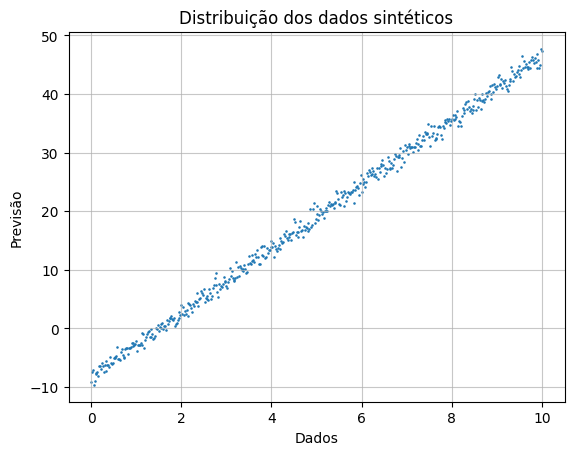

In [132]:
B, W = np.meshgrid(b_values, w_values)

plt.scatter(x, y_true, s=0.7)

plt.title("Distribuição dos dados sintéticos")
plt.xlabel("Dados")
plt.ylabel("Previsão")

plt.grid(alpha=0.7)
plt.show()

Aqui temos uma distribuição de pontos com uma tendencia visível de desenvolvimento, porém, eles não se organizam em uma reta clara. Dado esse conjunto, nos testamos vários b's e $\omega$'s para descobrir aquele que gera a menor Loss. Na realidade, existem algoritmos determinísticos que calculam isso, o desenvolvimento é análogo ao da equação (2), caso o leitor queira ver por si mesmo. Veja abaixo como que a função de perda se comporta mudando as variáveis.

Ademais, o gráfico da regressão linear tem um termo denominado $R^2$. Não se preocupe agora, será explicado em seguida.

In [133]:
def quadrados_minimos(w:tuple)->float:
    """
    Função de erro J(w), essa se difere da anterior pois tem o coeficiente linear

    entradas: 
    - w_ols -- Pesos totais
    saída:
    - Erro quadrático médio 
    """ 
    y_pred = x*w[1]+w[0]

    return 1/2*np.mean((y_true - y_pred)**2)
    


#Matriz que vai armazenar os erros
J = np.zeros_like(B)

menor_loss=float("inf")
coef_menor_loss = [0, 0]

for i in range(B.shape[0]):
    for j in range(B.shape[1]):
        w_teste=[B[i, j], W[i, j]]

        J[i, j] = quadrados_minimos(w_teste)
        if menor_loss>J[i, j]:
            menor_loss = J[i, j]
            coef_menor_loss = w_teste.copy()


y_pred = coef_menor_loss[1]*x+coef_menor_loss[0]

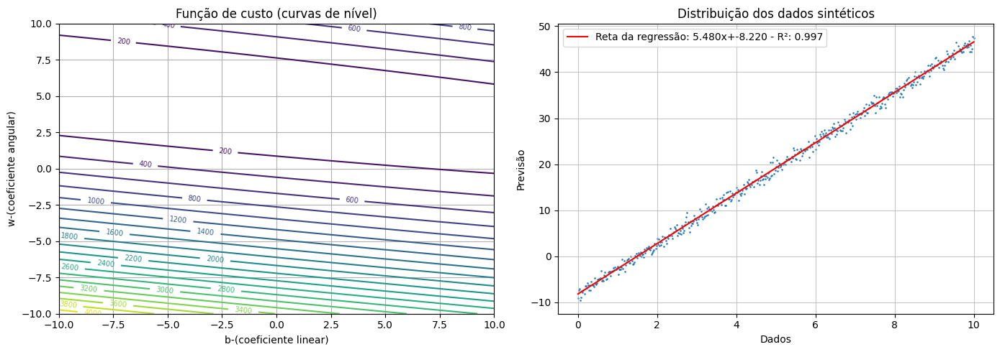

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))


# Desenha as linhas de nível para valores constantes de J
contorno = axes[0].contour(
    B,
    W,
    J,
    levels=25
)

axes[0].clabel(contorno, inline=True, fontsize=7)

axes[0].set_xlabel("b-(coeficiente linear)")
axes[0].set_ylabel("w-(coeficiente angular)")
axes[0].set_title(
    "Função de custo (curvas de nível)"
)
axes[0].grid()

#-----------------------------------------------------------------

axes[1].scatter(x, y_true, s=0.7)
axes[1].plot(x, y_pred, label=f"Reta da regressão: {coef_menor_loss[1]:.3f}x+{coef_menor_loss[0]:.3f} - R²: {r2_score(y_true,y_pred):.3f}", color="red")

axes[1].set_title("Distribuição dos dados sintéticos")
axes[1].set_xlabel("Dados")
axes[1].set_ylabel("Previsão")

axes[1].grid(alpha=0.7)
axes[1].legend()

plt.tight_layout()
plt.show()

A esquerda temos o gráfico com as curvas de nível da função de perda e a direita a reta da regressão. A reta encontrada é uma boa estimativa, mas não a melhor, já que não usamos a solução analítica determinísticas. Entretanto, ela serve para demonstrar o conceito. Como estimativa de erro da reta, é comumente usado três parâmetros: erro absoluto médio, erro quadrático médio e $R^2$. Os dois primeiros já foram apresentados anteriormente, mas o que é esse último?

Como estimativa da qualidade da previsão da reta, poderíamos usar o erro quadrático médio. Entretanto, esse parâmetro não da uma análise simples de forma direta, ele é quão melhor em relação a o que? Por isso, podemos dividi-lo por um outro erro quadrático médio padrão de todas as reta: chamaremos ele de baseline. 

O que é esse baseline? Imagine que façamos o seguinte modelo: para qualquer pergunta, ele responderá com a média dos valores observados. Normalmente, esse não é um bom modelo, mas ele é simples e fácil de se calcular, o suficiente para podermos usá-lo como comparativo para diversas análises: se o seu modelo é pior que esse baseline, já é uma ótima métrica para repensá-lo a fundo. Para obtermos a relação entre as estimativas, dividimos os erros médios:

$$\frac{RSS}{TSS}=\frac{\sum_{i=1}^n[y_i-y_{pred-i}]^2}{\sum_{i=1}^n[y_i-\overline{y}]^2}$$

Com:

$RSS = \sum_{i=1}^n[y_i-y_{pred-i}]^2$ sendo o **Residual Square Sum**


$TSS = \sum_{i=1}^n[y_i-\overline{y}]^2$ sendo o **Total Square Sum**

Com isso, temos formas fáceis de avaliar desempenho: se $0\leq \frac{RSS}{TSS}<1$, o modelo é melhor que o baseline em prever os resultados, se $\frac{RSS}{TSS}=1$, o modelo é tão bom quanto o baseline e se $\frac{RSS}{TSS}>1$ o modelo é pior que o baseline. Além disso, quanto mais próximo do 0, melhor a reta. Existe um último passo, para chegarmos na formula final, fazemos $R^2=1-\frac{RSS}{TSS}$. Porque? Interpretação, agora temos que o 1 é o melhor valor possível para uma reta e todos os valores acima de zero representam um modelo melhor que o baseline. Além disso, se $R^2< 0$ sabemos que o modelo é pior que o baseline e se $R^2= 0$ ele é tão bom quanto. Isso permite interpretar um $R^2=0.45$ como $45 \ %$ menos erro que o baseline. Com isso, a formula final ficaria assim:

$$R^2=1-\frac{\sum_{i=1}^n[y_i-y_{pred-i}]^2}{\sum_{i=1}^n[y_i-\overline{y}]^2}$$

<a id='toc0_'></a>[[1]](#toceq_1_)



---
### <a id='toc1_1_3_'></a>[Evidenciação do problema](#toc0_)

#### <a id='toc1_1_3_1_'></a>[Sistemas mal-condicionados](#toc0_)

Para demonstrar o problema do mal-condicionamento, imagine que tenhamos uma matriz X em que as colunas $x_1, x_2, x_3 ..., x_p$ sejam fortemente correlacionadas <a id='toc0_'></a>[[1]](#toceq_1_) <a id='toc0_'></a>[[3]](#toceq_3_), como que a predição funciona nessa situação? O exemplo a seguir não é um caso real e sim um toy-model. Ademais, ele foi feito com apenas duas variáveis, $x_1$ e $x_2$, para facilitar a visualização, mas o programa já está otimizado para $x_p$.

In [ ]:
n = 20
x1 = rng.normal(0, 1, n)
x2 = x1 + rng.normal(0, 0.08, n)

# Espaço real do problema, o normal no final é um "ruído"
y = 3*x1 + 3*x2 + rng.normal(0, 0.25, n)
X = np.column_stack([x1, x2]) # n exemplos com 2 atributos

p_shape = X.shape[1]

# centralizando os dados, se não fizermos isso, vai ter um fator de deslocamento b chamado de intercepto. Centralizando, forçamos o plano a passar por (0,0,0) e diminuímos o numero de parâmetros de (b, x1, x2) para (x1, x2) - ficaria menos didático caso não fizesse-mos.
X = X - X.mean(axis=0)
y = y - y.mean()


In [ ]:
# Tiramos o intercept na centralização, por isso o fit_intercept ta False
modelo = LinearRegression(fit_intercept=False)
modelo.fit(X, y)

# OLS é de Ordinary Least Square, ou MQO de mínimos quadrados ordinários, são os nomes usados. OLS será o nome padrão do modelo pelo notebook
#Recuperando os coeficiente
w_ols = modelo.coef_

#Fazemos genérico aqui para se voce quiser testar com mais x's
print("Coeficientes encontrados por OLS:")
for i in range(p_shape):
    print(f"w{i+1} = {w_ols[i]:.3f}")

print("\nCorrelação entre os x's:")
# O corrcoef cria uma matriz de correlação, vamos só pegar os termos superiores
matriz_correlacao = np.corrcoef(X, rowvar=False)

for i in range(p_shape):
    for j in range(i+1, p_shape):
            print(f"entre x{i+1} e x{j+1}: {matriz_correlacao[i,j]:.4f}")

Coeficientes encontrados por OLS:
w1 = 2.470
w2 = 3.509

Correlação entre os x's:
entre x1 e x2: 0.9972


Apenas para esclarecer, a correlação entre $x_1$ e $x_2$ é calculada fazendo:

$$coor(X)=\frac{\sigma_{mín}}{\sigma_{máx}}$$

<a id='toc0_'></a>[[3]](#toceq_3_)

Em que $\sigma_{máx}$ é o maior valor singular de X e $\sigma_{mín}$ é o menor valor singular de X. Quando mais próximos de 1, maior a correlação entre eles.

Nesse toy-model, correlação alta implica em mal-condicionamento, mas isso não é absoluto.

In [137]:
# Como x1 =~ x2, temos que y=~(w1+w2)x1.
# Portanto, escolhemos pares de w1 e w2 que dão a mesma soma.

# Criamos vários pesos de soma iguais, para o caso de p_shape = 2 bastaria ter um +2 e um -2. Porém, o programa é genérico, por isso usamos a identidade de que cossenos igualmente espaçados tem soma 0.
pesos = [
    tuple(w_ols[i] for i in range(p_shape)),
    tuple(w_ols[i]+2*(np.cos(i*(2*np.pi/p_shape))) for i in range(p_shape)),
    tuple(w_ols[i]+2*(np.cos(i*(2*np.pi/p_shape)+np.pi)) for i in range(p_shape)),
]

nomes = [
    "OLS",
    f"OLS + {tuple(float(2*(np.cos(i*(2*np.pi/p_shape)))) for i in range(p_shape))}",
    f"OLS + {tuple(float(2*(np.cos(i*(2*np.pi/p_shape)+np.pi))) for i in range(p_shape))}"
]

In [138]:
def minimum_square_error(w_ols:tuple)->float:
    """
    Função de erro J(w)

    entradas: 
    - w_ols -- Pesos totais
    saída:
    - Erro quadrático médio 
    """ 
    y_pred = X@w_ols

    return 1/2*np.mean((y - y_pred)**2)


for nome, w in zip(nomes, pesos):
    print(
        f"{nome:18s} ",
        ", ".join([f"w{i+1}={w[i]:6.2f}" for i in range(p_shape)]),
        f"MSE = {minimum_square_error(w):.4f}"
    )

OLS                 w1=  2.47, w2=  3.51 MSE = 0.0158
OLS + (2.0, -2.0)   w1=  4.47, w2=  1.51 MSE = 0.0313
OLS + (-2.0, 2.0)   w1=  0.47, w2=  5.51 MSE = 0.0313


Nota-se que J(w) não é igual para os três casos, isso é algo esperado, tendo em vista a correlação apresentada. Como a correlação de $x_1$ e $x_2$ não é 1, existe uma variação pequena quando mudamo-os. Isso indica que o vale do espaço de J(w) é achatado, mas não plano. Isso será melhor discutido no gráfico de custo abaixo.

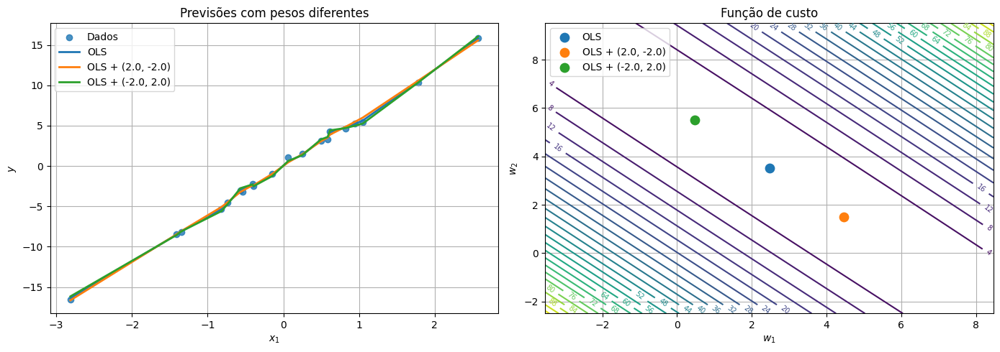

In [139]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Fig 1 (previsão) --------------------------------------------------------

# Só pro gráfico ficar bonitinho, ela retorna uma lista com os indices de X ordenados. Assim, não modificamos X
ordem = np.argsort(X[:, 0])

# Como os x's são aproximadamente iguais, vamos projetar o gráfico só em x1, já que o resto dos gráficos vão ser quase que iguais
axes[0].scatter(
    X[:, 0],
    y,
    alpha=0.8,
    label="Dados"
)

for nome, w in zip(nomes, pesos):

    y_pred = sum(w[i]*X[:, i] for i in range(len(X[0])))
    # y_pred = w1*X[:, 0] + w2*X[:, 1]

    axes[0].plot(
        X[ordem, 0],
        y_pred[ordem],
        linewidth=2,
        label=f"{nome}"
    )

axes[0].set_xlabel("$x_1$")
axes[0].set_ylabel("$y$")
axes[0].set_title(
    "Previsões com pesos diferentes"
)
axes[0].grid()
axes[0].legend()

# Fig 2 ------------------------------------------------------------------------

#Vamos plotar só w{l} e w{m}, mas basta mudar o índice do w_ols que você vê combinações dos outros pesos (todos são aproximadamente iguais)
#Possíveis valores de w{l} e w{m}

l=0
m=1

w1_vals = np.linspace(w_ols[l] - 6, w_ols[l] + 6, 250)
w2_vals = np.linspace(w_ols[m] - 6, w_ols[m] + 6, 250)

W1, W2 = np.meshgrid(w1_vals, w2_vals)


#Matriz que vai armazenar os erros
J = np.zeros_like(W1)

for i in range(W1.shape[0]):
    for j in range(W1.shape[1]):
        w_teste=w_ols.copy()
        w_teste[0]=W1[i, j]
        w_teste[1]=W2[i, j]

        J[i, j] = minimum_square_error(w_teste)

# Desenha as linhas de nível para valores constantes de J
contorno = axes[1].contour(
    W1,
    W2,
    J,
    levels=25
)

axes[1].clabel(contorno, inline=True, fontsize=7)

for nome, w in zip(nomes, pesos):
    axes[1].scatter(
        w[l],
        w[m],
        s=80,
        label=nome
    )

axes[1].set_xlabel(f"$w_{l+1}$")
axes[1].set_ylabel(f"$w_{m+1}$")
axes[1].set_title(
    "Função de custo"
)
axes[1].grid()
axes[1].legend()

plt.tight_layout()
plt.show()


Analisando os gráficos os pontos feitos acima fazem sentido. 

As três retas do gráfico da esquerda, que são projeções da previsão multivariada, estão basicamente sobrepostas, mostrando que, mesmo com 3 conjuntos de pesos diferentes, a previsão y é quase que igual. Se houvesse apenas essas retas sem os pesos, seria quase que impossível determinar qual a melhor reta que descreve esse conjunto, confirmando o ponto levantado durante a introdução.

As 'retas' do gráfico da direita representam as curvas de nível da função de custo. No caso abordado, as curvas de nível são elipses muito alongadas, por isso tem essa aparência. Perceba que os três pontos são colineares, logo, ao colocar uma elipse extremamente alongada sobre eles nota-se que o ponto central quase que cai no mesmo nível que os outros. Isso mostra que o seus custos são extremamente próximos um dos outros, tornando difícil discernir qual a melhor reta, já que o vale é quase que plano. Isso é uma consequência da correlação ainda não é exatamente 1.0. Caso fosse, significa que preferir $x_1$ a $x_2$ não teria diferença, resultando nos tres pontos estando na exata mesma curva de nível, que seriam representadas por elipses infinitamente longas (basicamente duas retas).

Caso isso ocorresse, poderíamos representar uma variável como uma combinação linear da outra, diminuindo o número de exemplos úteis do sistema, podendo gerar, até, um sistema sub-determinado.


---
#### <a id='toc1_1_3_2_'></a>[Sistemas sub-determinados](#toc0_)


Mas isso se trata somente de sistemas mal-condicionados, e os sub-determinados?

Ele é construído de forma análoga ao visto acima, mas usando uma quantidade bem diferente de exemplos e atributos. Imagine n equações que contenham p atributos, normalmente, isso seria considerado um sistema sem solução única, e usaremos disso para demonstrar o caso exposto na introdução.

In [140]:

n = 8   # número de exemplos
p = 20  # número de atributos

X = rng.normal(0, 1, size=(n, p))
X = X - X.mean(axis=0)

# Pesos usados para gerar os dados
w_true = rng.normal(0, 1, size=p)

# Sem ruído para evidenciar a não unicidade da solução
y = X @ w_true
y = y - y.mean()

rank = np.linalg.matrix_rank(X) # O rank da matrix é semelhante a sua dimensão (no sentido de espaço vetorial que ela define). É o número de linhas que são linearmente independentes.

print(f"Número de exemplos: {n}")
print(f"Número de atributos: {p}")
print(f"Rank de X: {rank}")

Número de exemplos: 8
Número de atributos: 20
Rank de X: 7


Note que o Rank é 7 e não 8. Tal fato pode parecer estranho, mas era esperado após centralizarmos. Quando centralizamos o sistema, forçamos o sistema a passar por um ponto definido, o que diminui o posto do problema por eliminar o termo constante da equação, o que gera uma dependência linear entre as linhas. Isso resulta na seguinte situação, há 20 atributos e 7 equações lineares, isso significa que há 13 graus de liberdade no espaço dos coeficientes que não alteram a solução do sistema <a id='toc0_'></a>[[3]](#toceq_3_). 

In [141]:
modelo = LinearRegression(fit_intercept=False)
modelo.fit(X, y)

w_ols = modelo.coef_

print("\nErro da solução OLS:")
print(minimum_square_error(w_ols))


Erro da solução OLS:
7.442563677090034e-30


In [142]:
# Como so queremos a solução, estamos buscando o núcleo de X. usaremos a decomposição SVD (já que a matriz é retangular)
_, _, Vt = np.linalg.svd(X, full_matrices=True)

# As linhas de Vt depois do rank formam uma base para o núcleo de X. Escolhemos uma direção qualquer do núcleo que ainda soluciona Xv=0
null_space = Vt[rank:]
v_null = null_space[0]

# Normalizamos apenas para facilitar a interpretação
v_null = v_null / np.linalg.norm(v_null)

#Isso é apenas para mostrar que Xv_null=0
print("\nNorma de X @ v_null:")
print(np.linalg.norm(X @ v_null))


Norma de X @ v_null:
7.43207042519283e-16


In [143]:
# gerando varias soluções 
alphas = [-10, -5, 0, 5, 10]

#Aqui temos um vetor w_alpha que continua sendo solução do sistema, ja que Xv_null é zero, Xw_alpha=Xw_ols. Isso mostra que qualquer alpha soluciona o sistema
pesos = [
    w_ols + alpha * v_null
    for alpha in alphas
]

# Comparando o erro
for alpha, w in zip(alphas, pesos):

    mse = minimum_square_error(w)

    print(
        f"alpha = {alpha:>3} "
        f"MSE = {mse:.12f} "
        f"||w||₂ = {np.linalg.norm(w):.3f}"
    )


alpha = -10 MSE = 0.000000000000 ||w||₂ = 10.384
alpha =  -5 MSE = 0.000000000000 ||w||₂ = 5.730
alpha =   0 MSE = 0.000000000000 ||w||₂ = 2.799
alpha =   5 MSE = 0.000000000000 ||w||₂ = 5.730
alpha =  10 MSE = 0.000000000000 ||w||₂ = 10.384


In [144]:
# Pegamos uma direção pertencente ao espaço de linhas de X (para não zerar)
v_signal = Vt[0]

v_signal = v_signal / np.linalg.norm(v_signal)

def custo(alpha, beta):
    """
    Função custo em duas direções
    
    entrada:
    alpha -- eixo de várias soluções com o mesmo erro
    beta -- direção para diferenciar as soluções de J(w)
    saída:
    erro da função com alpha e beta
    """
    w = (w_ols + alpha * v_null + beta * v_signal)

    return minimum_square_error(w)

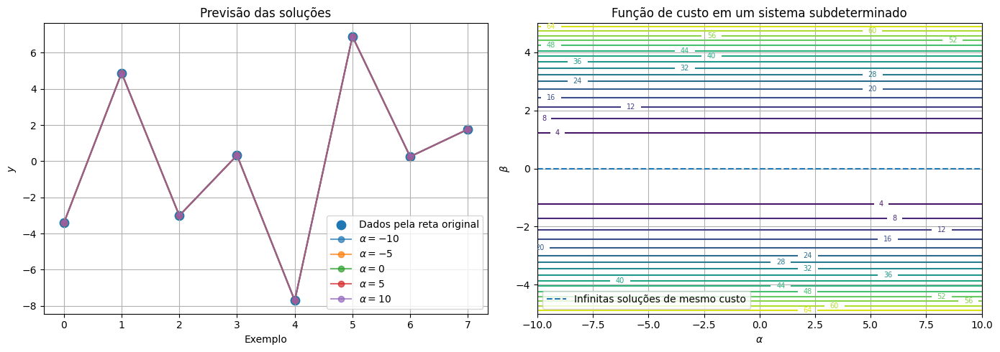

In [145]:
alpha_vals = np.linspace(-10, 10, 200)
beta_vals = np.linspace(-5, 5, 200)

A, B = np.meshgrid(alpha_vals, beta_vals)

J = np.zeros_like(A)

for i in range(A.shape[0]):
    for j in range(A.shape[1]):

        J[i, j] = custo(
            A[i, j],
            B[i, j]
        )

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Fig 1 (previsões) -----------------------------------------

axes[0].scatter(
    np.arange(n),
    y,
    s=80,
    label="Dados pela reta original"
)

for alpha, w in zip(alphas, pesos):

    y_pred = X @ w

    axes[0].plot(
        np.arange(n),
        y_pred,
        marker="o",
        alpha=0.7,
        label=rf"$\alpha={alpha}$"
    )

axes[0].set_xlabel("Exemplo")
axes[0].set_ylabel("$y$")
axes[0].set_title("Previsão das soluções")

axes[0].grid()
axes[0].legend()

#Fig 2 (função custo) -------------------------------------------

contorno = axes[1].contour(
    A,
    B,
    J,
    levels=20
)

axes[1].clabel(
    contorno,
    inline=True,
    fontsize=7
)

axes[1].axhline(
    0,
    linestyle="--",
    label="Infinitas soluções de mesmo custo"
)

axes[1].set_xlabel(r"$\alpha$")
axes[1].set_ylabel(r"$\beta$")

axes[1].set_title("Função de custo em um sistema subdeterminado")

axes[1].grid()
axes[1].legend()

plt.tight_layout()
plt.show()

Novamente, as previsões se concretizam. A esquerda vemos um gráfico de previsões de y para oito exemplos de previsões para 5 curvas distintas. Nota-se que, mesmo para equações diferentes que usam pesos distintos, a taxa de previsão é igual, mostrando que, em sistemas sub-determinados, há mais de uma equação que gera o mesmo resultado.

Obviamente, isso é válido para pontos que fornecemos ao modelo. Para pontos fora dos exemplos podemos ter previsões distintas.

Ademais, olhando para o gráfico da esquerda, cada uma dessas soluções tem o mesmo valor de custo, somente quando saímos da solução com o $\beta$ que esse custo se altera.

Portanto, como escolher uma solução dentre infinitas soluções boas?

---
### <a id='toc1_1_4_'></a>[L2: penalização nos pesos](#toc0_)

Para resolver os problemas mal-condicionados devemos saber como escolher os coeficientes. Para isso, a função de penalização deve forçar hipóteses na estrutura do espaço de solução e ter preferencias que façam com que soluções indiferenciáveis se tornem diferenciáveis. Mas como essa função se comporta?

Imagine que modifiquemos a função de custo para a forma vista em (2) (o fator de $\frac{1}{2}$ é posto apenas para facilitar a derivação). O termo final é algo deliberadamente inserido para ampliar a pergunta da loss original: vamos de **Qual o melhor w que explica o problema** para **Qual o melhor w que explica o problema e gera coeficientes balanceados** <a id='toc0_'></a>[[1]](#toceq_1_) <a id='toc0_'></a>[[3]](#toceq_3_). Isso é a ideia que L2 introduz e para representar isso no espaço de solução adicionamos um termo como visto na equação (2).

$$(2)\qquad J_{Ridge}(w)=\frac{1}{2}||Xw-y||_2^2+\frac{\lambda}{2}||w||_2^2$$

Desenvolvendo o último termo, a função de penalização dos pesos surge naturalmente

$$||w||_2^2=w^{\dagger}w=w^Tw=\sum_i w_i^2=R(w)$$

Interpretando essa função, ela penalizando pesos muito altos, já que seu crescimento é de forma quadrática. Por isso, a função de L2 da preferencia a respostas distribuídas entre os termos, algo que a função loss original não possui.

Com o $R(w)$, podemos usar a equação (2) para derivar o gradiente dessa função. Como $R(w)$ tem a mesma forma geral de $J(w)$ (no sentido de ambos serem funções de $f(x)=||x||_2^2$), elas são deriváveis, por isso, o seu gradiente é dado por (todos os $\dagger$ serão substituídos por $T$, já que, nesse cenário, são iguais):

$$\nabla J_{L2}(w)= \nabla (\frac{1}{2}||Xw-y||_2^2+\frac{\lambda}{2}||w||_2^2)= \nabla(\frac{1}{2}(Xw-y)^T(Xw-y)+\frac{\lambda}{2}w^Tw)$$

O primeiro termo fica

$$\nabla\frac{1}{2}(Xw-y)^T(Xw-y)=\nabla\frac{1}{2}(w^TX^TXw-w^TX^Ty-y^TXw+y^Ty)$$

Como $w^TX^Ty$ é escalares, temos que $w^TX^Ty=(w^TX^Ty)^T=y^TXw$

$$\nabla\frac{1}{2}(Xw-y)^T(Xw-y)=\nabla\frac{1}{2}(w^TX^TXw-2y^TXw-y^Ty)=X^TXw-X^Ty=\nabla J(w)$$

Agora, desenvolvendo o segundo termo

$$\nabla R(w)=\nabla\frac{\lambda}{2}w^Tw=\lambda w$$

Rearranjando os termos, temos que o gradiente da função $J_{L2}(w)$ é dado por (3).

$$(3)\qquad \nabla J_{L2}(w) = X^T(Xw-y)+\lambda w$$

Agora, podemos achar o mínimo do gradiente, que será no:

$$(4)\qquad X^T(Xw-y)+\lambda w = 0 \rightarrow (X^TX + \lambda I)w=X^Ty \rightarrow w_{Ridge}=(X^TX + \lambda I)^{-1}X^Ty$$

Nota-se que, se não tivéssemos um termo a mais, o passo final dessa operação assume que $X^TX$ é uma matriz inversível. Porém, a vantagem do Ridge (a regularização L2) é que precisamos assumir que $(X^TX+\lambda I)$ é inversível. Não desenvolveremos isso aqui, mas, mesmo quando $X^TX$ é singular, o termo anterior sempre é inversível para $\lambda >0$, o que é algo incrivelmente valioso do método. Quando $\lambda I$ é somado a $X^TX$, ele aumenta a diagonal principal, tornando a matriz mais resistente a singularidade pois aumenta o autovalor ($\sigma_i^2$) em um fator de $\lambda$. Isso permite que o passo do gradiente seja mais comportado e estável, analisando o resultado por decomposição SVD (decompondo $X$ em $U\Sigma V^T$) <a id='toc0_'></a>[{2}](#tocap_2_), nota-se que o passo $w_i$ é proporcional a $\frac{\sigma_i}{\sigma_i^2+\lambda}$ <a id='toc0_'></a>[[3]](#toceq_3_). Com isso, nos extremos temos:

$$\text{para }\sigma_i^2 \gg \lambda\text{, temos: }\frac{\sigma_i}{\sigma_i^2+\lambda}\approx \frac{1}{\sigma_i} \\ \text{para }\sigma_i^2 \ll \lambda\text{, temos: }\frac{\sigma_i}{\sigma_i^2+\lambda}\approx \frac{\sigma_i}{\lambda}$$

Para visualizarmos, veja o gráfico abaixo.

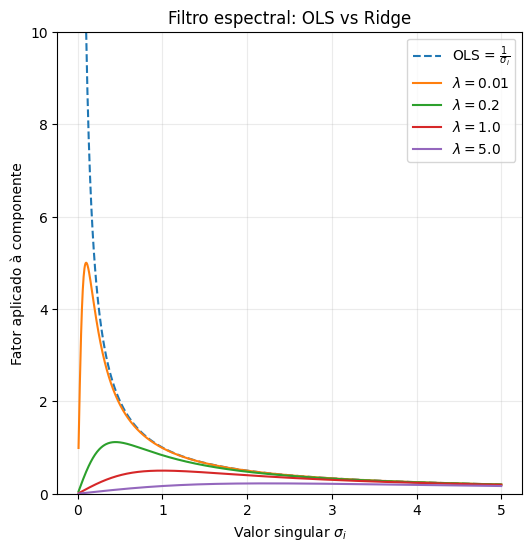

In [146]:
# Valores singulares
sigma=np.linspace(0.01, 5, 1000)

#valores reguladores
lambdas=[0.01, 0.2, 1.0, 5.0]

ols_filter= 1/sigma

plt.figure(figsize=(6,6))

plt.plot(sigma, ols_filter, linestyle="--", label=r"OLS = $\frac{1}{\sigma_i}$")

for lam in lambdas:
    ridge_filter = sigma/(sigma**2 + lam)

    plt.plot(
        sigma,
        ridge_filter,
        label= rf"$\lambda ={lam}$"
    )


plt.xlabel(r"Valor singular $\sigma_i$")
plt.ylabel("Fator aplicado à componente")
plt.title("Filtro espectral: OLS vs Ridge")

plt.ylim(0, 10)
plt.grid(alpha=0.25)
plt.legend()

plt.show()


Veja como para o OLS comum, valores singulares muito pequenos e não nulos acabam explodindo quando $\sigma_i\to 0^+$, amplificando componentes associadas a direções mal determinadas. Já quando adicionamos o fator de $\lambda$, isso se torna mais comportado.

Assim, vemos que o L2 é uma boa solução para o problema da decisão entre variáveis correlacionadas ao estabilizar a solução, mas nem sempre é fácil encontrar o $min_w(||Xw-y||_2^2+\lambda||w||_2^2)$. Para situações como essa, existem técnicas que analisam a geometria do espaço de soluções do L2, na qual minimiza-se o termo $||Xw-y||_2^2$ e restringe-se a função $R(w)$ com uma constante $C$, resultando na forma (5). Para cada $\lambda$ existe uma formulação correspondente de $C$ e vice-versa <a id='toc0_'></a>[[3]](#toceq_3_) <a id='toc0_'></a>[[6]](#toceq_6_).

$$(5)\qquad \text{Ache }min(||Xw-y||_2^2)\text{ com }\sum_i w_i^2\leq C$$

Como isso se comporta no espaço da Loss? Para analisar isso, imagine uma função loss artificial com mínimos em $(2,0.5)$ (os números são arbitrários, poderiam ser substituídos por qualquer outros valores). Ademais, essa loss tera um comportamento do tipo:

$$J(w_1, w_2)=(w_1-2)^2+2(w_2-0.5)^2$$

Mais uma vez, tudo escolhido é completamente arbitrário, particularmente os coeficientes de $w_1$ e $w_2$ foram propositalmente escolhidos para serem diferentes. Isso gera uma loss elíptica, tornando mais geral o conceito que queremos discorrer abaixo.

In [147]:
# Espaço dos parâmetros
w1= np.linspace(-3, 3, 400)
w2= np.linspace(-3, 3, 400)

# Combinação de parâmetros
W1, W2 = np.meshgrid(w1, w2)

# Loss artificial
J=(W1-2)**2+2*(W2-0.5)**2

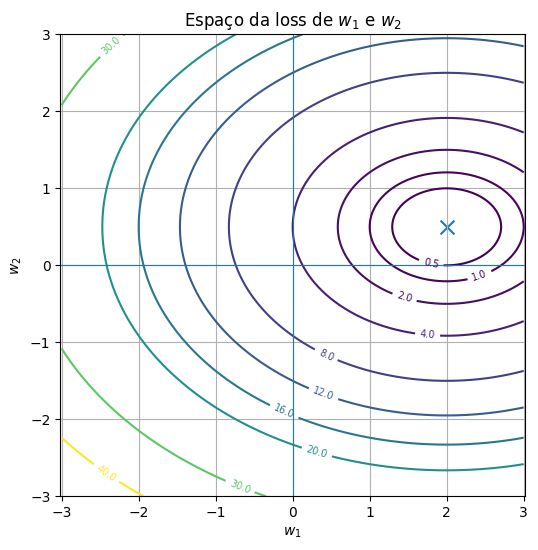

In [148]:
plt.figure(figsize=(6,6))

contorno = plt.contour(
    W1,
    W2,
    J,
    levels=[0.5, 1, 2, 4, 8, 12, 16, 20, 30, 40]
)

plt.clabel(contorno, inline=True, fontsize=7)

plt.scatter(2, 0.5, marker="x", s=100)

plt.xlabel(r"$w_1$")
plt.ylabel(r"$w_2$")
plt.title(r"Espaço da loss de $w_1$ e $w_2$")

plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)

plt.axis("equal")
plt.grid()
plt.show()

Aqui vemos varias elipses centradas em $(2, 0.5)$, cada uma aumentando a loss na medida em que se afastam de seu centro. Contudo, note que a região permitida pela restrição do L2 não está centrado em $(2, 0.5)$, ele parte do $(0,0)$, isso resulta em algo interessante demonstrado abaixo.

Para construir a região $w_1^2 + w_2^2\leq C$, usaremos um theta para calcular $w_1$ e $w_2$. Além disso, vamos escolher um $C<||(2,0.5)||_2^2$, já que isso resultará em uma análise interessante.

In [ ]:

theta=np.linspace(0, 2*np.pi, 500)

#Raio arbitrário
r=1
#Para esclarecimento, r²=C

l2_w1=r*np.cos(theta)
l2_w2=r*np.sin(theta)

#Essa mascara define quais combinações de pontos podem entrar na consideração da solução ótima
mask_l2=W1**2 + W2**2 <= r**2


In [150]:
# Achando a solução pelo método L2
J_l2=np.where(mask_l2, J ,np.inf)
idx_l2 = np.unravel_index(np.argmin(J_l2), J_l2.shape)
w_l2= (W1[idx_l2],W2[idx_l2])

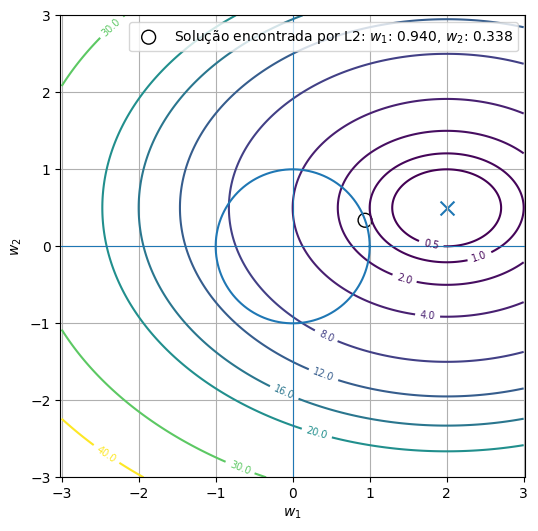

In [151]:
plt.figure(figsize=(6, 6))

contorno = plt.contour(
    W1,
    W2,
    J,
    levels=[ 0.5, 1, 2, 4, 8, 12, 16, 20, 30, 40]
)

plt.clabel(contorno, inline=True, fontsize=7)

plt.plot(l2_w1, l2_w2)

plt.scatter(2, 0.5, marker="x", s=100)
plt.scatter(w_l2[0], w_l2[1], marker="o", facecolor="none", edgecolors="black", s=100, label= fr"Solução encontrada por L2: $w_1$: {w_l2[0]:.3f}, $w_2$: {w_l2[1]:.3f}")

plt.xlabel(r"$w_1$")
plt.ylabel(r"$w_2$")

plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)

plt.axis("equal")
plt.legend()
plt.grid()
plt.show()

(5) define uma n-bola, que é uma forma geral de uma esfera preenchida de n dimensões, disponível para a busca (o caso usado é bidimensional, mas é fácil notar a generalização para dimensões superiores). Para um dado $\sum_i w_i^2=C$ a solução ótima existe na tangente da curva de nível $J(w)=c$ (não confundir $c$ com $C$) que tangencia a n-bola externamente, caso a solução ótima esteja fora do espaço de admissão. Como essa hiperesfera é suave, essa solução, normalmente, se encontra distante dos eixos puros <a id='toc0_'></a>[[3]](#toceq_3_), geralmente ela não favorece soluções de coeficiente zero.

Contudo, o computador não consegue, sempre, zerar o gradiente por ser uma operação computacionalmente cara para problemas muito grandes, tornando, as vezes, inviável o computar. Por isso, usa-se uma técnica chamada *Gradient Descent*, em que usa-se o gradiente atual para 'caminhar' em direção de uma minimização da loss. Abandonando o formalismo matricial, podemos escrever (3) como a equação (6). Nesse contexto, vamos abandonar a convenção do $\frac{1}{2}$, já que a literatura sobre Weight Decay não a usa e não há impacto na validade do resultado usar esse termo ou não.

$$(6)\qquad \nabla J_{L2}(w_t)=\frac{\partial J(w_t)}{\partial w} + 2\lambda w_t$$


Então, os novos pesos $w_{t+1}$ dessa equação são dados por $w_{t+1}=w_t-\eta(\nabla J_{L2}(w_t))$ que se expande para a equação (7).

$$(7)\qquad
w_{t+1}= (1-2\lambda \eta) w_t - \eta\frac{\partial J}{\partial w}$$

Isso simboliza algo muito importante, a cada atualização, o peso sofre uma contração segundo o termo $(1-2\lambda \eta) w_t$. Tal ocorrência da o nome para esse tipo de técnica de Weight Decay <a id='toc0_'></a>[[4]](#toceq_4_), em que os pesos passam a importar quando entra-se no domínio de loss baixa. Dentro desse domínio, a função ajusta os pesos com pouca variação de $J(w)$.

Isso resolve de uma forma muito elegante o problema do mal-condicionamento, como $X^TX+\lambda I$ é sempre inversível para $\lambda>0$, todo caso tem uma solução fechada no L2, dentro dos problemas abordados nesse notebook. Esse fato não só é bom para mal-condicionamento, ele estruturalmente resolve o problema do sub-determinação. Contudo, essa é a melhor forma de resolver o problema?

---
### <a id='toc1_1_5_'></a>[L1: regularização geométrica](#toc0_)



L1 é, de certa forma, quase que idêntico ao L2, alterando somente o termo $R(w)$. Contudo, qual outra característica que seria desejada numa outra função? Mesmo que L2 gere pesos distribuídos e possamos usar a técnica da restrição geométrica do espaço, ele ainda assim não tenta minimizar o somatório dos pesos caso isso custe muita loss. A pergunta agora é **e se a solução não tem uma contribuição útil vinda de alguns poucos pesos?**

L1 não deseja distribuir os pesos, ele quer gerar esparsidade no espaço de soluções, mas como fazer isso? É necessário punir pesos baixos mais violentamente para que o máximo de zeros apareça quando o peso não contribui para a solução. Para isso, usa-se uma outra minimização sem ser a $||w||_2^2$ (para manter a mesma derivação feita em (2), porém, como não há necessidade de se preocupar com a derivação de $R(w)$ nesse caso, não sera adicionado o $\frac{1}{2}$ nele):

$$J_{L1}(w)=\frac{1}{2}||Xw-y||_2^2+\lambda ||w||_1$$

O último termo pode ser desenvolvido facilmente para:

$$R(w)=||w||_1=\sum_{i=1}^{p} |w_i|$$

De forma análoga a feita na seção de L2, podemos restringir a geometria do problema para compreender como que essa função se comporta no quesito do deslocamento no hyperespaço da loss. Ao aplicar a mesma restrição que fizemos em L2, obtemos a equação (8).

$$(8)\qquad |w_1|+|w_2|+...|w_p|\leq C$$

Para, novamente, facilitarmos a visualização desse conceito, veja abaixo o gráfico formado por essa equação em um caso bidimensional.

In [152]:
C = 1

#Note que o ultimo termo é igual ao primeiro nos dois, isso é para a forma geométrica se completar, já que o matplotlib não faz isso por conta própria.
l1_w1 = np.array([C, 0, -C, 0, C])
l1_w2 = np.array([0, C, 0, -C, 0])

#Essa mascara define quais combinações de pontos podem entrar na consideração da solução ótima
mask_l1 = np.abs(W1)+np.abs(W2)<= C

In [153]:
#achando a solução pelo método l1
J_l1=np.where(mask_l1, J ,np.inf)
idx_l1 = np.unravel_index(np.argmin(J_l1), J_l1.shape)
w_l1= (W1[idx_l1],W2[idx_l1])

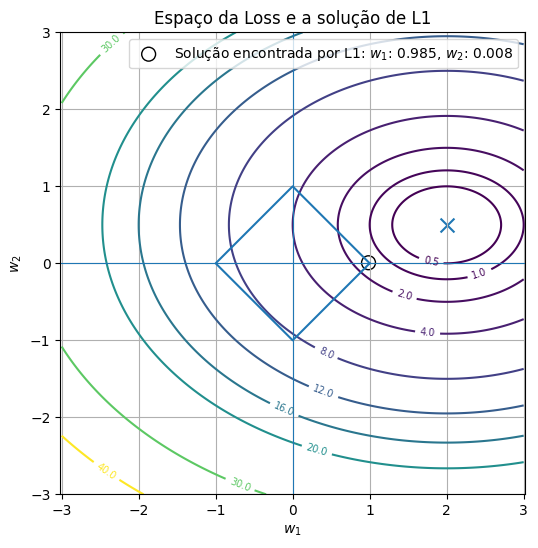

In [154]:
plt.figure(figsize=(6, 6))

contorno = plt.contour(
    W1,
    W2,
    J,
    levels=[ 0.5, 1, 2, 4, 8, 12, 16, 20, 30, 40]
)

plt.clabel(contorno, inline=True, fontsize=7)

plt.plot(l1_w1, l1_w2)

plt.scatter(2, 0.5, marker="x", s=100)
plt.scatter(w_l1[0], w_l1[1], marker="o", facecolor="none", edgecolors="black", s=100, label= fr"Solução encontrada por L1: $w_1$: {w_l1[0]:.3f}, $w_2$: {w_l1[1]:.3f}")

plt.xlabel(r"$w_1$")
plt.ylabel(r"$w_2$")
plt.title("Espaço da Loss e a solução de L1")

plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)

plt.axis("equal")
plt.legend()
plt.grid()
plt.show()

Isso define um n-cross-polytope, que é uma forma geral de um octaedro preenchido de n dimensões, ou um losango preenchido no caso de n=2, dentro do espaço (<a id='toc0_'></a>[[3]](#toceq_3_), especificamente a figura 3.11). Algo interessante dessa forma geométrica é que suas quinas definem pontos onde algum dos pesos é $0$, isso é uma característica extremamente importante para o modelo. Se as curvas de nível forem analisadas para $J(w)$, nota-se que, para $J(w)=c$, o primeiro ponto a ser tocado, que também é solução para (8), normalmente é uma das quinas. Isso não é regra, já que não há nenhuma restrição dessa tangencia ocorrer no meio da aresta, porém, o L1 favorece esse tipo de solução. Isso significa que, ao diminuir a loss, o primeiro ponto a ser usado como resposta tem algum peso zero ou próximo disso. Com isso, fica evidente que L1 presa por esparsidade.

Ademais, isso pode ser visualizado pela derivada da equação. Porém, deve-se ter cuidado ao derivar esse $R(w)$, já que essa função não é derivável em todo o seu domínio, por isso, deve-se separa-la em três partes:

$$\frac{d R(w)}{dw}=1 \text{ para }w>0$$
$$\frac{d R(w)}{dw}=-1 \text{ para }w<0$$

Ambas formulas são facilmente deriváveis, mas o que ocorre em $R(0)$? Essa função não é derivável em $0$, mas isso não significa que não exista forma de extrair uma solução. Usando o conceito de subgradiente <a id='toc0_'></a>[[6]](#toceq_6_) <a id='toc0_'></a>[{1}](#tocap_1_), vemos que:

$$\partial |w|_{w=0}=[-1,1]\text{, logo, }\lambda R(w)\text{ será: } \partial \lambda |w|_{w=0}=[-\lambda,\lambda]$$

Com isso, podemos avaliar qual a condição de ótimo dessa função. Vamos derivar a função $J_{L1}(w)$, para o ponto de ótimo queremos aproximadamente $0 \in \partial J(w)$, isso significa:

$$0 \in \frac{\partial J(w)}{\partial w} + [-\lambda, \lambda]$$

Isso só é possível para a condição (9).

$$(9)\qquad |\frac{\partial J(w)}{\partial w}| \leq \lambda$$

Essa inequação é mais poderosa do que parece. Ela mostra que, para gradientes suficientemente pequenos, o gradiente naquela posição possui magnitude menor ou igual a $\lambda$, então $\omega = 0$ é solução de ótimo para aquela posição. Logo, a regularização L1 também nulifica features que são pequenas demais para justificar a sua existência. Diferente da regularização L2, em que o caso $\frac{\partial J(w)}{\partial w}+\lambda w=0$ tem de forma pontual a solução $w=0$, L1 tem essa solução dentro de um intervalo todo.

Por isso, a regularização L1 realiza uma seleção de features e zera os coeficientes associados as features que não contribuem para a solução. Isso é fantástico principalmente para problemas sub-determinado, já que L1 elimina uma parte dos parâmetros que os exemplos não explicam, ajudando a aumentar a eficacia dos exemplos e, em casos de uma regressão linear, possibilita aproximar uma boa solução para o problema que antes era posto como sem solução determinada <a id='toc0_'></a>[[3]](#toceq_3_) <a id='toc0_'></a>[[5]](#toceq_5_).

Pela mesma razão, regularização L1 é capaz de evitar overfitting. Ela assume que a verdadeira solução do problema é aproximadamente esparsa.

Essa discussão é extremamente valiosa para o entendimento teórico, mas ainda apenas tangencia o uso prático do L1. Se quisermos convergir o modelo e calcular o erro, como fazemos o gradiente dessa função $R(w)$? Para isso, vamos analisar caso a caso como a derivada de $R(w)$ se comporta.

1. Caso $w>0$: $\nabla J_{L1}(w)=\nabla J(w) + \lambda$

2. Caso $w<0$: $\nabla J_{L1}(w)=\nabla J(w) - \lambda$

3. Caso $w=0$: $\nabla J_{L1}(w)\in \nabla J(w) - \lambda[-1,1]$

Como $J(w)=\frac{1}{2}(w-z)^2$ (vamos olhar peso a peso para ter uma análise mais minuciosa), com z sendo a resposta do ponto analisado, a derivada de $J_{L1}(w)$ ficaria $(w-z)+R'(w)$. Agora, a pergunta é: existe algum $w$ que resulta em $J'_{L1}(w)=0$ ?

Para 1., a solução seria $z-\lambda$, mas isso não é solução para todo $z$, somente para $z>\lambda$, de forma análoga, para 2., a solução também é única $w=z+\lambda$ e necessita da condição $z<-\lambda$. Agora, para o caso 3. é feita uma operação de conjuntos, resultando na condição $0\in [-z-\lambda, -z+\lambda]$, isso significa que z tem a condição de $-\lambda \leq z \leq \lambda$.

Com isso, temos a função por partes:

$$w(z)=
\begin{cases}
z - \lambda \text{, para }z>\lambda \\
0 \text{, para } -\lambda \leq z \leq \lambda \\
z+\lambda \text{, para } z<-\lambda
\end{cases}
$$

Teoricamente, isso já é uma formula resultante para a solução ótima por partes. Contudo, existe uma forma mais compacta para essa equação. Para preservar a forma da função, usa-se $max(|z|-\lambda, 0)$, isso da consistência no resultado, já que para $z>\lambda$, $-\lambda \leq z \leq \lambda$, e $z<-\lambda$ os resultados ficam consistentes para um $|w|$. Para recuperar o sinal, usa-se uma função chamada $sign(x)$. Ela é definida da seguinte forma:

$$sign(x)=
\begin{cases}
\ \ \ 1 \text{, para }x>0 \\
\ \ \ 0 \text{, para } x=0 \\
-1 \text{, para } x<0
\end{cases}
$$

Assim, a formula final dos pesos depois da regularização L1 é dado por (10). O nome dela é **soft-threshold**, já que ela tenta se aproximar suavemente em uma resposta que passe por um threshold, dando o nome para a função. Não confunda o suave com a definição matemática de diferenciabilidade, já que isso seria falso nessa função, e nem que ele é o motivo para o termo **soft** da expressão. Esse termo vem de uma comparação com outro regularizador chamado **hard-threshold**, o qual não será desenvolvido aqui.

$$(10)\qquad w_{i}(z)=sign(z)max(|z|-\lambda,0)\qquad$$

<a id='toc0_'></a>[[5]](#toceq_5_)

Essa função se apresenta como um deslocamento da reta de peso com o centro dela zerado, veja mais abaixo.

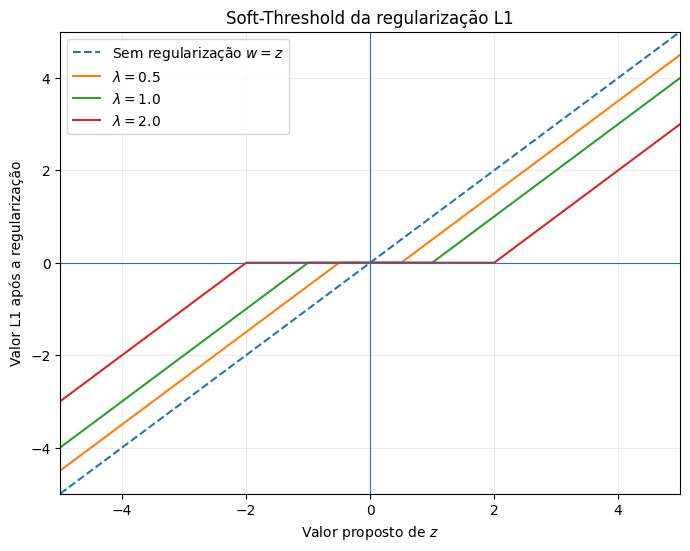

In [155]:

z=np.linspace(-5, 5, 1000)

lambdas = [0.5, 1.0, 2.0]

plt.figure(figsize=(8,6))

plt.plot(
    z,
    z,
    linestyle="--",
    label=r"Sem regularização $w=z$"
)

for lam in lambdas:
    w = np.sign(z)*np.maximum(abs(z)-lam,0)

    plt.plot(
        z,
        w,
        label= rf"$\lambda ={lam}$"
    )

plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)

plt.xlabel(r"Valor proposto de $z$")
plt.ylabel("Valor L1 após a regularização")
plt.title("Soft-Threshold da regularização L1")

plt.ylim(-5, 5)
plt.xlim(-5, 5)
plt.grid(alpha=0.25)
plt.legend()

plt.show()

Não podemos confundir essa formula com a "derivada" de L1, a função dada por $R(w)$ continua sem derivada continua. Então, como aplicar essa formula? Imagine uma função Loss total dada por $F(w)=f(w)+\lambda |w|$, para analisarmos o proximo passo da descida do gradiente, fazemos $z=w_t-\eta f'(w_t)$. Com esse novo $z$, passamos a escutar a regularização L1 para julgar esse passo, fazemos

$$w_{t+1}=argmin_{w}[\frac{1}{2\eta}(w-z)^2+\lambda |w|]$$

Cada termo tem uma preferencia clara, o primeiro termo $\frac{1}{2\eta}(w-z)^2$ tenta não se afastar da direção que os dados prevem e o segundo termo $\lambda |w|$ busca minimizar $w$. Nesse caso que um termo de $\eta$ surgiu, isso significa que o nosso threshold mudou. Como estamos fazendo $w_t-\eta \nabla f(w_t)$, o termo de threshold muda para $\eta \lambda$, A solução para a equação acima está na equação (10), logo, a formula final de $w_{t+1}$ é dada por (11).

$$(11)\qquad w_{t+1}=sign(w_t-\eta f'(w_t))max(|w_t-\eta f'(w_t)|-\eta\lambda, 0)$$

Contudo, e se o fenômeno real for distribuído de tal forma que todos os parâmetros tem interações muito limitadas, mas essenciais? Infelizmente, casos como esses podem fazer com que o L1 descarte informação útil, por isso, devemos pensar **eu realmente acredito que a solução do meu problema é esparsa?** Ademais, o fato de uma característica ser eliminada por L1 não significa que ela não tenha informação útil. Em caso de sistemas mal-condicionados, a regularização L1 pode detectar informação redundante e decidir que um parâmetro explica tanto quanto outro.

Além disso, sem padronização L1 pode penalizar termos de forma desigual baseado na unidade. Imagine a uma altura em metros e outras em milímetros, o regularizador L1 tende a preferir uma altura em milímetros simplesmente pela magnitude <a id='toc0_'></a>[[1]](#toceq_1_) <a id='toc0_'></a>[[3]](#toceq_3_). Por isso, devemos nos atentar a comparar dados não padronizados, já que algumas não fazem sentido.

Fora em casos de ortogonalidade, uma estratégia comum para resolver Lasso (L1) é *Coordinate Descent*, que é parecido com o *Gradient Descent*, mas atualiza peso a peso em sequência ao invés de dar um passo na direção de um vetor específico. Essa técnica é a utilizada pela principal biblioteca desse notebook, o ``scikit-learn`` 

Com tudo isso, como podemos aplicar-los? 

---
### <a id='toc1_1_6_'></a>[Exemplos teóricos](#toc0_)

#### <a id='toc1_1_6_1_'></a>[Valor de casas em terrenos](#toc0_)


Comecemos agora a aplicar tudo que foi aprendido. Imagine a seguinte situação: **queremos prever o valor de um terreno baseado na área disponível**. Contudo, não temos apenas um dado de área, temos 4 valores que sofrem com erros de medida (vindos de equipamentos, aproximações, etc). Isso é um caso emblemático de um problema mal-condicionado.

Um adendo, usaremos as funções <span style="color:#97E1F1">RidgeCV</span>() e <span style="color:#97E1F1">LassoCV</span>(). A sigla CV significa **Cross Validation**, isso é um modelo que varia alguns hiperparâmetros das funções Lasso e Ridge para encontrar a força regularizadora ideal da regressão. No caso do Lasso e Ridge, esse hiperparâmetro é o alpha, que é o $\lambda$ da formula exposta na introdução. Manipula-lo irá alterar a força da regularização, $\lambda$'s muito baixo reduzem o modelo a um análogo da regularização linear convencional. Já $\lambda$'s muito altos destroem a informação do problema e gerar underfitting, que é quando um modelo não consegue se adaptar aos dados por alguma restrição <a id='toc0_'></a>[[1]](#toceq_1_).

In [156]:
n=300 #exemplos

#areas disponíveis
area_real= rng.uniform(low=100,high=1000,size=n)

# lei do preço das casas
preco= 100000+2000*area_real+rng.normal(0,40000,size=n)

erro=0.002

#areas em cada unidade, inserimos um erro para simbolizar erros de conversão
area_m2=area_real*(1+rng.normal(0,erro,size=n))
area_cm2=area_real*10000*(1+rng.normal(0,erro,size=n))
area_pes2=area_real*10.7639*(1+rng.normal(0,erro,size=n))
area_palmo2=area_real*(1+rng.normal(0,erro,size=n))/(0.22**2)

X=np.column_stack([
    area_m2,
    area_cm2,
    area_pes2,
    area_palmo2
])
print("A matrix de áreas é:")
display(pd.DataFrame(X, columns=["Área em m²","Área em cm²","Área em pés²","Área em palmos²"]))
print(f"Seu rank é: {np.linalg.matrix_rank(X)}")
print(f"Seu número de condição é: {np.linalg.cond(X)}")

p_shape = X.shape[1]
matriz_correlacao = np.corrcoef(X, rowvar=False)
print("\nCorrelação:")
for i in range(p_shape):
    for j in range(i+1, p_shape):
            print(f"entre x{i+1} e x{j+1}: {matriz_correlacao[i,j]:.6f}")

A matrix de áreas é:


,Área em m²,Área em cm²,Área em pés²,Área em palmos²
0,632.006331,6.324051e+06,6778.125508,13038.470867
1,869.178634,8.645061e+06,9292.698800,17829.160761
2,104.222668,1.042248e+06,1120.522942,2152.968103
3,866.647337,8.654786e+06,9319.596593,17978.652678
4,657.769480,6.578684e+06,7075.453973,13556.772071
...,...,...,...,...
295,717.094191,7.156473e+06,7696.617114,14818.920791
296,120.900704,1.212176e+06,1305.527248,2498.760558
297,460.315756,4.588131e+06,4942.843136,9501.948586
298,889.522076,8.904447e+06,9534.056064,18377.129458


Seu rank é: 4
Seu número de condição é: 3956729.0846257573

Correlação:
entre x1 e x2: 0.999975
entre x1 e x3: 0.999974
entre x1 e x4: 0.999974
entre x2 e x3: 0.999978
entre x2 e x4: 0.999973
entre x3 e x4: 0.999976


Veja que a matrix é muito correlacionada, mas não perfeitamente. Isso permite com que o rank da matrix seja 4. Nota-se que o número de condição é extremamente alto, mas isso não se deve unicamente a correlação dos dados. Por mais alto que ela seja, existe uma diferença de escala muito grande entre alguns valores, isso acaba inflando muito esse número. Por isso, usa-se o StandardScaler para corrigir isso, para que haja uma comparação justa entre os termos.

Além disso, o StandardScaler impede que modelos como o Lasso escolham um dado simplesmente pelo tamanho dele, já que ele deixa todos os valores na mesma escala.

Antes de analisarmos os modelos, precisamos particionar os nossos dados em treino e teste.

In [157]:
#Poderíamos aplicar StandardScaler no X antes de separa-lo, mas isso resultaria em dados de teste sendo escalados. Esse problema é nomeado como data leakage, que é como se já soubéssemos as respostas que queremos prever, dando uma falsa sensação de sucesso
X_train, X_test, y_train, y_test =train_test_split(
    X,
    preco,
    test_size=0.25,
    random_state=42
) 

# A função make_pipeline encadeia as transformações. O ridge é a regularização L2, o Lasso é a regularização L1 e o LinearRegression é o modelo sem regularização
ols_linear = make_pipeline(
    StandardScaler(),
    LinearRegression()
)

ols_L2 = make_pipeline(
    StandardScaler(),
    RidgeCV()
)

ols_L1= make_pipeline(
    StandardScaler(),
    LassoCV()
)

In [158]:
#Treinando modelo sem regressão
ols_linear.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('linearregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value
"mean_ mean_: ndarray of shape (n_features,) or NoneThe mean value for each feature in the training set.Equal to ``None`` when ``with_mean=False`` and ``with_std=False``.","ndarray[float64](4,)","[ 558.59,5584944.06, 6012.78, 11544.47]"


In [159]:
#treinando modelo L2
ols_L2.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('ridgecv', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value
"mean_ mean_: ndarray of shape (n_features,) or NoneThe mean value for each feature in the training set.Equal to ``None`` when ``with_mean=False`` and ``with_std=False``.","ndarray[float64](4,)","[ 558.59,5584944.06, 6012.78, 11544.47]"


In [160]:
#treinando modelo L1
ols_L1.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('lassocv', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value
"mean_ mean_: ndarray of shape (n_features,) or NoneThe mean value for each feature in the training set.Equal to ``None`` when ``with_mean=False`` and ``with_std=False``.","ndarray[float64](4,)","[ 558.59,5584944.06, 6012.78, 11544.47]"


Agora, está na hora de validar os três modelos para as casas.

OLS: w0= 202147.682, w1= 540652.533, w2= 382381.141, w3= -604537.716, 
Ridge: w0= 133792.662, w1= 157585.265, w2= 141322.263, w3= 87886.186, 
Lasso: w0= 520011.056, w1= 51.543, w2= 0.000, w3= 0.000, 


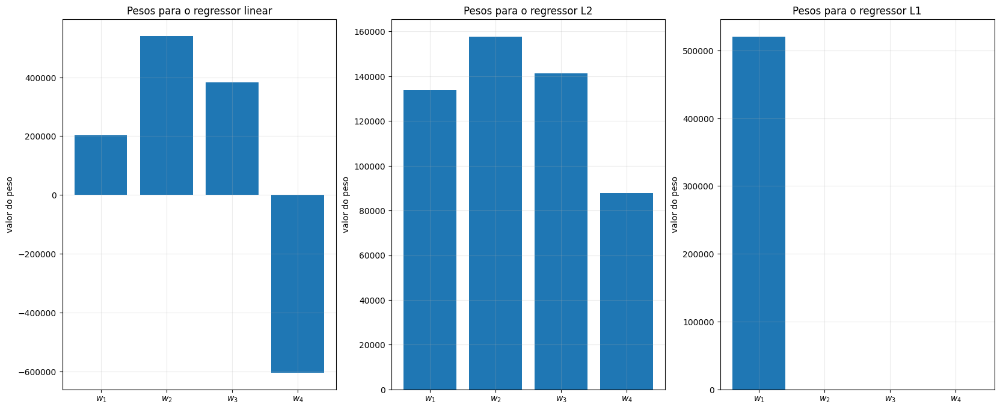

In [161]:
y_linear_pred = ols_linear.predict(X_test)
y_L2_pred = ols_L2.predict(X_test)
y_L1_pred = ols_L1.predict(X_test)

#Recuperando os coeficientes
coef_linear=ols_linear[-1].coef_
coef_L2=ols_L2[-1].coef_
coef_L1=ols_L1[-1].coef_

print("OLS: ", end="")
for i, coef in enumerate(coef_linear):
    print(rf"w{i}= {coef:.3f}, ", end="")
print()

print("Ridge: ", end="")
for i, coef in enumerate(coef_L2):
    print(rf"w{i}= {coef:.3f}, ", end="")
print()

print("Lasso: ", end="")
for i, coef in enumerate(coef_L1):
    print(rf"w{i}= {coef:.3f}, ", end="")
print()

# ---------------------------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(20, 8))

axes[0].bar([r"$w_1$", r"$w_2$", r"$w_3$", r"$w_4$"], coef_linear)
axes[0].grid(alpha=0.25)

axes[0].set_ylabel("valor do peso")
axes[0].set_title("Pesos para o regressor linear")

#-----------------------------------------------------------------

axes[1].bar([r"$w_1$", r"$w_2$", r"$w_3$", r"$w_4$"], coef_L2)
axes[1].grid(alpha=0.25)

axes[1].set_ylabel("valor do peso")
axes[1].set_title("Pesos para o regressor L2")

#-----------------------------------------------------------------

axes[2].bar([r"$w_1$", r"$w_2$", r"$w_3$", r"$w_4$"], coef_L1)
axes[2].grid(alpha=0.25)

axes[2].set_ylabel("valor do peso")
axes[2].set_title("Pesos para o regressor L1")
plt.show()

Note como a discussão acima se concretizou, o OLS conseguiu achar uma resposta, mas os seus coeficientes são instáveis e pouco interpretáveis <a id='toc0_'></a>[[1]](#toceq_1_) <a id='toc0_'></a>[[3]](#toceq_3_), já que todos os dados são extremamente correlacionados. Já o Ridge buscou uma solução equilibrada que preservou coeficientes redundantes. Note que os coeficientes são estranhamente equilibrados para escalas tão diferentes de números, isso é devido ao StandardScaler que deixa todos os valores na mesma magnitude (padronização). Por fim, o Lasso buscou zerar coeficientes redundantes ou sem importância, concentrando a explicação dentro de poucas features.

In [162]:
# Erro do modelo linear
MAE_linear = mean_absolute_error(y_test,y_linear_pred)
RMSE_linear = mean_squared_error(y_test,y_linear_pred)**(1/2)
R2_linear = r2_score(y_test, y_linear_pred)

#Erro do modelo L2
MAE_L2 = mean_absolute_error(y_test,y_L2_pred)
RMSE_L2 = mean_squared_error(y_test,y_L2_pred)**(1/2)
R2_L2 = r2_score(y_test, y_L2_pred)

#Erro do modelo L1  
MAE_L1 = mean_absolute_error(y_test,y_L1_pred)
RMSE_L1 = mean_squared_error(y_test,y_L1_pred)**(1/2)
R2_L1 = r2_score(y_test, y_L1_pred)

print(f"Erro absoluto médio do modelo OLS: {MAE_linear:.2f}")
print(f"Erro quadrático médio regular do modelo OLS: {RMSE_linear:.2f}")
print(f"R² do OLS: {R2_linear:.5f}")
print("------------------------------------------------------------------")
print(f"Erro absoluto médio do modelo Ridge: {MAE_L2:.2f}")
print(f"Erro quadrático médio regular do modelo Ridge: {RMSE_L2:.2f}")
print(f"R² do Ridge: {R2_L2:.5f}")
print("------------------------------------------------------------------")
print(f"Erro absoluto médio do modelo Lasso: {MAE_L1:.2f}")
print(f"Erro quadrático médio regular do modelo Lasso: {RMSE_L1:.2f}")
print(f"R² do Lasso: {R2_L1:.5f}")

Erro absoluto médio do modelo OLS: 34839.45
Erro quadrático médio regular do modelo OLS: 43078.12
R² do OLS: 0.99335
------------------------------------------------------------------
Erro absoluto médio do modelo Ridge: 33767.17
Erro quadrático médio regular do modelo Ridge: 42316.79
R² do Ridge: 0.99358
------------------------------------------------------------------
Erro absoluto médio do modelo Lasso: 33563.21
Erro quadrático médio regular do modelo Lasso: 42136.35
R² do Lasso: 0.99364


A princípio, esse resultado pode se mostrar decepcionante para toda a discussão que tivemos acima, mesmo que o erro do OLS seja levemente pior, ainda não é suficiente para descartar o modelo como um bom candidato para uma previsão (até porque ele é mais barato do que o Lasso). Contudo, os testes realizados avaliam somente interpolação, como os modelos saem para casos de extrapolação?


In [163]:
n=300 #exemplos

#areas disponíveis
area_real= rng.uniform(low=1000,high=10000,size=n)

# lei do preço das casas
preco= 100000+2000*area_real+rng.normal(0,40000,size=n)

erro=0.002

#areas em cada unidade, inserimos um erro para simbolizar erros de conversão
area_m2=area_real*(1+rng.normal(0,erro,size=n))
area_cm2=area_real*10000*(1+rng.normal(0,erro,size=n))
area_pes2=area_real*10.7639*(1+rng.normal(0,erro,size=n))
area_palmo2=area_real*(1+rng.normal(0,erro,size=n))/(0.22**2)

X=np.column_stack([
    area_m2,
    area_cm2,
    area_pes2,
    area_palmo2
])

y_linear_pred = ols_linear.predict(X)
y_L2_pred = ols_L2.predict(X)
y_L1_pred = ols_L1.predict(X)

MAE_linear = mean_absolute_error(preco,y_linear_pred)
RMSE_linear = mean_squared_error(preco,y_linear_pred)**(1/2)
R2_linear = r2_score(preco, y_linear_pred)

#Erro do modelo L2
MAE_L2 = mean_absolute_error(preco,y_L2_pred)
RMSE_L2 = mean_squared_error(preco,y_L2_pred)**(1/2)
R2_L2 = r2_score(preco, y_L2_pred)

#Erro do modelo L1  
MAE_L1 = mean_absolute_error(preco,y_L1_pred)
RMSE_L1 = mean_squared_error(preco,y_L1_pred)**(1/2)
R2_L1 = r2_score(preco, y_L1_pred)

print(f"Erro absoluto médio do modelo OLS: {MAE_linear:.2f}")
print(f"Erro quadrático médio regular do modelo OLS: {RMSE_linear:.2f}")
print(f"R² do OLS: {R2_linear:.5f}")
print("------------------------------------------------------------------")
print(f"Erro absoluto médio do modelo Ridge: {MAE_L2:.2f}")
print(f"Erro quadrático médio regular do modelo Ridge: {RMSE_L2:.2f}")
print(f"R² do Ridge: {R2_L2:.5f}")
print("------------------------------------------------------------------")
print(f"Erro absoluto médio do modelo Lasso: {MAE_L1:.2f}")
print(f"Erro quadrático médio regular do modelo Lasso: {RMSE_L1:.2f}")
print(f"R² do Lasso: {R2_L1:.5f}")

Erro absoluto médio do modelo OLS: 49811.94
Erro quadrático médio regular do modelo OLS: 62920.91
R² do OLS: 0.99985
------------------------------------------------------------------
Erro absoluto médio do modelo Ridge: 40540.95
Erro quadrático médio regular do modelo Ridge: 51156.95
R² do Ridge: 0.99990
------------------------------------------------------------------
Erro absoluto médio do modelo Lasso: 49014.12
Erro quadrático médio regular do modelo Lasso: 60300.47
R² do Lasso: 0.99986


Além da seed 42, foram testadas algumas outras para avaliar a consistência, como a 43, a 44 e a 1029, desta afirmação: para extrapolação, o erro quadrático médio e o erro absoluto médio é maior no OLS e no L1 do que no L2. Foi visualizado que essa diferença ficou de até 20.000, mas não é possível afirmar que isso é consistente. Isso não conclui que um é necessariamente melhor que o outro, apenas que, na média, L2 gera coeficientes que extrapolam melhor seguindo a mesma lei linear, para o positivo, que o OLS e o L1. Isso não significa que o OLS e o L1 são modelos ruins, basta analisar o $R^2$, o contexto da ordem de grandeza e o espaço que eles começam a falhar que podemos inferir que o modelo, na realidade, pode ser até mais vantajoso nesse caso do que o L2.

Devemos lembrar também que essa extrapolação assume que a lei do valor de terrenos continua igual para terrenos maiores, caso ela mude, talvez os três modelos falhem miseravelmente. Mas, existe algum preferível nesse intervalo? Sim, como discutimos anteriormente, sabendo as hipóteses do L1 e L2, podemos interpretar os seus coeficientes, dificilmente poderíamos fazer isso com o OLS nesse caso. Entretanto, e se isso não fosse o que desejamos?

Para argumentar em defesa do OLS, pense no seguinte: a maioria dos terrenos no Brasil orbitam em volta de $680  \ m^2$ <a id='toc0_'></a>[{3}](#tocap_3_). Logo, para um modelo de previsão de terrenos populares, ele realiza o seu trabalho de forma excepcional na média. Ademais, realizar uma regressão linear normal é computacionalmente mais barato do que L1 (O L2 tem solução fechada, então, normalmente, tem um custo parecido), logo, será que realmente vale a pena escolher um modelo em que a precisão do $R^2$ muda na terceira casa depois da vírgula? Por fim, o erro aparece de forma mais gritante porque a escala dos números é muito maior, logo, mesmo que ele erre pouco, esse número é grande e cresce quadraticamente.

Entretanto, também há bons argumentos contra ele. Querendo ou não, nessa seed escolhida, o erro do L2 é menor que o do OLS e do L1. Para terrenos gigantes, como para latifúndios ou grandes mansões, isso significa que, em média, os compradores que usam o OLS e o L1 podem pagar mais ou menos em um terreno. Nesse cenário, nota-se uma certa vantagem em usa-lo como bom candidato substituto do OLS comum e do L1.

Veja que o teste de extrapolação para baixo não foi realizado, isso é proposital, já que extrapolar para baixo faz com que o ruído introduzido fique na ordem de grandeza do valor calculado, tornando quase qualquer preço não confiável. Tal caso simplesmente não contribui para a discussão, já que seria uma previsão do gerador de números aleatórios do numpy mais do que sobre o problema em si.

Por fim, os coeficientes. Independente do quão acurado cada um seja, o OLS gera pesos que, mesmo que cheguem na resposta, não tem significado plausível. Como que aumentar a área em $m^2$ aumenta o preço, mas aumentar em $palmos^2$ não? O OLS gera uma resposta, mas ela não é fisicamente confiável ou interpretável, é apenas um padrão que o modelo encontrou. Já o L2 e o L1 tem interpretações bem plausíveis pois sabemos o que eles estão supondo, sendo melhores para interpretar tendencias de algo. Então, talvez não estejamos buscando um modelo mais preciso ou mais leve, talvez queremos analisar como uma tendencia se comporta. Assim, com as hipóteses corretas, L2 e L1 adquirem novas praticidades perante as abordagens normais.

Antes de partirmos para a próxima seção, queria tirar um momento para discutir algo interessante. Veja o $R^2$ do Ridge e, depois, o MAE/RMSE dele, notou algo? Como pode um $R^2$ tão próximo de $1$ com um erro tão grande? Quanto mais subimos a escala, maior é a variância do $y$, isso faz com que erros que pareçam grandes sejam minúsculos perante a esse valor, diminuindo o $q^2$ discutido em [Regressão Linear simples](#toc1_1_2_). 

Isso é uma lição importante: não interprete nenhuma métrica de forma isolada, todas elas são relativas ao contexto do seu problema. Poderíamos supor que um MAE/RMSE dessa magnitude comprovavam que o problema é incapaz de prever qualquer coisa, enquanto o modelo da sessão final, spoiler de [Modelos preditivos](#toc1_1_7_4_), é fantástico por ter um erro de apenas 18. Esse não é o caso, o modelo de previsão de casas, supondo que ela siga a regra proposta, é fenomenal, enquanto o outro... veremos mais tarde.

Por isso, coisas que pareçam conflitantes, na realidade, podem coexistir a depender do contexto do problema. Sempre se atente a isso para não tirar conclusões estatísticas precipitadas. 

#### <a id='toc1_1_6_2_'></a>[Sistema Linear possível e indeterminado](#toc0_)



Agora, quero que o leitor imagine o seguinte cenário: você recebeu uma medida que apresenta 200 parâmetros, mas somente 100 medidas. Isso é um caso absurdo de sistema sub-determinado, metade dos parâmetros são direções independentes no espaço dos coeficientes que não são determinados pelos exemplos. Em um mundo onde só podemos usar OLS, isso seria um caso que voltaria direto para o laboratório, não porque o OLS não pode achar uma solução (ele acha), mas ela não é única e nem confiável. Porém, como será que as novas técnicas reagem a isso?


In [ ]:
n = 100   # número de exemplos
p = 200  # número de atributos

X = rng.normal(0, 1, size=(n, p))

# Pesos usados para gerar os dados
w_true = np.zeros(p, dtype=float)
# w_true = rng.normal(0, 1, size=p)
numeros = rng.choice(range(p), size=10, replace=False)

w_true=list(w_true)

#Para garantir que não haverá 0, vou espelhar o intervalo
for i in numeros:
    w_true[i]=rng.choice(range(1, 100))*rng.choice([-1,1])

w_true=np.array(w_true)

# Sem ruído para evidenciar a não unicidade da solução
y = X @ w_true

Aqui pegamos um caso extremo, escolhemos 10 parâmetros para realmente impactarem na resposta. A princípio, isso é para demonstrar o potencial do L1 em uma resposta esparsa, mas mostraremos o caso em que isso é falso mais para frente.

In [165]:
#Poderíamos aplicar StandardScaler no X antes de separa-lo, mas isso resultaria em dados de teste sendo escalados. Esse problema é nomeado como data leakage, que é como se já soubéssemos as respostas que queremos prever, dando uma falsa sensação de sucesso
X_train, X_test, y_train, y_test =train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42
) 

# A função make_pipeline encadeia as transformações. O ridge é a regularização L2, o Lasso é a regularização L1 e o LinearRegression é o modelo sem regularização
ols_linear = make_pipeline(
    LinearRegression()
)

ols_L2 = make_pipeline(
    RidgeCV()
)

ols_L1= make_pipeline(
    LassoCV()
)

Veja que aqui o StandardScaler foi retirado, porque? Simples, não há necessidade de padronizar os dados. Todos estão na mesma proporção e foram feitos propositalmente assim, logo, para mater os coeficientes estimados diretamente comparáveis não vamos aplicar o StandardScaler.

In [166]:
#Treinando modelo sem regressão
ols_linear.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('linearregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,200
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [167]:
#treinando modelo L2
ols_L2.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('ridgecv', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,200
,"alphas alphas: array-like of shape (n_alphas,), default=(0.1, 1.0, 10.0)Array of alpha values to try.Regularization strength; must be a positive float. Regularizationimproves the conditioning of the problem and reduces the variance ofthe estimates. Larger values specify stronger regularization.Alpha corresponds to ``1 / (2C)`` in other linear models such as:class:`~sklearn.linear_model.LogisticRegression` or:class:`~sklearn.svm.LinearSVC`.If using Leave-One-Out cross-validation, alphas must be strictly positive.For an example on how regularization strength affects the model coefficients,see :ref:`sphx_glr_auto_examples_linear_model_plot_ridge_coeffs.py`.","(0.1, ...)"
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto false, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"scoring scoring: str, callable, default=NoneThe scoring method to use for cross-validation. Options:- str: see :ref:`scoring_string_names` for options.- callable: a scorer callable object (e.g., function) with signature ``scorer(estimator, X, y)``. See :ref:`scoring_callable` for details.- `None`: negative :ref:`mean squared error <mean_squared_error>` if cv is None (i.e. when using leave-one-out cross-validation), or :ref:`coefficient of determination <r2_score>` (:math:`R^2`) otherwise.",None
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the efficient Leave-One-Out cross-validation- integer, to specify the number of folds,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if ``y`` is binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used, else,:class:`~sklearn.model_selection.KFold` is used.Refer :ref:`User Guide <cross_validation>` for 

In [168]:
#treinando modelo L1
ols_L1.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('lassocv', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,200
,"eps eps: float, default=1e-3Length of the path. ``eps=1e-3`` means that``alpha_min / alpha_max = 1e-3``.",0.001
,"alphas alphas: array-like or int, default=100Values of alphas to test along the regularization path.If int, `alphas` values are generated automatically.If array-like, list of alpha values to use... versionchanged:: 1.7 `alphas` accepts an integer value which removes the need to pass `n_alphas`.",100
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto false, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"precompute precompute: 'auto', bool or array-like of shape (n_features, n_features), default='auto'Whether to use a precomputed Gram matrix to speed upcalculations. If set to ``'auto'`` let us decide. The Grammatrix can also be passed as an argument.",'auto'
,"max_iter max_iter: int, default=1000The maximum number of iterations.",1000


OLS: w0= 3.449, w1= -5.899, w2= 3.048, w3= -6.059, w4= 7.766, w5= 0.564, w6= 2.509, w7= 1.903, w8= 4.341, w9= -9.209, w10= -0.661, w11= 1.400, w12= 2.779, w13= 2.170, w14= -2.650, w15= -2.240, w16= 12.693, w17= -1.579, w18= -7.190, w19= 4.356, w20= 3.824, w21= -1.364, w22= -10.344, w23= -6.999, w24= 0.982, w25= 4.444, w26= -3.962, w27= 11.183, w28= 8.976, w29= -5.631, w30= 6.686, w31= -2.013, w32= 3.403, w33= 3.142, w34= 1.585, w35= -7.022, w36= -6.961, w37= 4.533, w38= 8.327, w39= -6.923, w40= -6.352, w41= 3.510, w42= -4.933, w43= -3.156, w44= 1.500, w45= -4.241, w46= -2.843, w47= -6.172, w48= 2.422, w49= -1.054, w50= -4.960, w51= -6.950, w52= -1.104, w53= -8.544, w54= 2.737, w55= -0.514, w56= -0.665, w57= -6.100, w58= -10.503, w59= -19.738, w60= 6.606, w61= 0.569, w62= 3.213, w63= 2.060, w64= -1.766, w65= -2.629, w66= 4.007, w67= 0.222, w68= 4.199, w69= -5.507, w70= 5.794, w71= -10.393, w72= 1.708, w73= 1.271, w74= 1.844, w75= -2.330, w76= -4.113, w77= -0.066, w78= -8.424, w79= 4.255

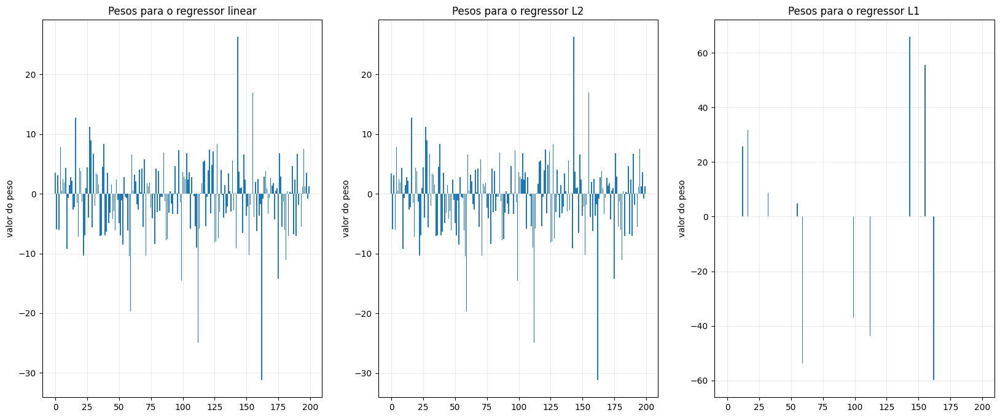

In [169]:
y_linear_pred = ols_linear.predict(X_test)
y_L2_pred = ols_L2.predict(X_test)
y_L1_pred = ols_L1.predict(X_test)

#Recuperando os coeficientes
coef_linear=ols_linear[-1].coef_
coef_L2=ols_L2[-1].coef_
coef_L1=ols_L1[-1].coef_

print("OLS: ", end="")
for i, coef in enumerate(coef_linear):
    print(rf"w{i}= {coef:.3f}, ", end="")
print()

print("Ridge: ", end="")
for i, coef in enumerate(coef_L2):
    print(rf"w{i}= {coef:.3f}, ", end="")
print()

print("Lasso: ", end="")
for i, coef in enumerate(coef_L1):
    print(rf"w{i}= {coef:.3f}, ", end="")
print()


# ---------------------------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(20, 8))

axes[0].bar(np.arange(p), coef_linear)
axes[0].grid(alpha=0.25)

axes[0].set_ylabel("valor do peso")
axes[0].set_title("Pesos para o regressor linear")

#-----------------------------------------------------------------

axes[1].bar(np.arange(p), coef_L2)
axes[1].grid(alpha=0.25)

axes[1].set_ylabel("valor do peso")
axes[1].set_title("Pesos para o regressor L2")

#-----------------------------------------------------------------

axes[2].bar(np.arange(p), coef_L1)
axes[2].grid(alpha=0.25)

axes[2].set_ylabel("valor do peso")
axes[2].set_title("Pesos para o regressor L1")
plt.show()

Aqui, algo extremamente interessante aparece ao leitor atento: veja o gráfico do L2 e do regressor linear padrão, você vê uma diferença grotesca entre eles? Como há poucos exemplo, nenhum dos dois consegue recuperar bem o verdadeiro vetor solução, mas porque será que ficaram tão parecidos? 

Veja a célula abaixo, vamos imprimir o alpha (simbolizado como $\lambda$ acima).

In [170]:
print(f"Lambda do Ridge: {ols_L2[-1].alpha_}")

Lambda do Ridge: 0.1


Esse valor é pequeno, isso significa que a regularização L2 não está impactando muito na resposta. Obviamente, há um impacto, se olharmos atentamente ao gráfico, existem colunas que mudam entre o linear e o ridge. Contudo, a força é pequena o suficiente para gerar uma forma parecida entre os dois.

Ademais, vale notar outra coisa também, o intervalo de busca do <span style="color:#97E1F1">RidgeCV</span>() tem como mínimo o valor de $\lambda$ de $0.1$. Logo, talvez ele buscasse um valor ainda menor que o tornaria ainda mais similar com o OLS.

In [171]:
# Erro do modelo linear
MAE_linear = mean_absolute_error(y_test,y_linear_pred)
RMSE_linear = mean_squared_error(y_test,y_linear_pred)**(1/2)
R2_linear = r2_score(y_test, y_linear_pred)

#Erro do modelo L2
MAE_L2 = mean_absolute_error(y_test,y_L2_pred)
RMSE_L2 = mean_squared_error(y_test,y_L2_pred)**(1/2)
R2_L2 = r2_score(y_test, y_L2_pred)

#Erro do modelo L1  
MAE_L1 = mean_absolute_error(y_test,y_L1_pred)
RMSE_L1 = mean_squared_error(y_test,y_L1_pred)**(1/2)
R2_L1 = r2_score(y_test, y_L1_pred)

print(f"Erro absoluto médio do modelo OLS: {MAE_linear:.2f}")
print(f"Erro quadrático médio regular do modelo OLS: {RMSE_linear:.2f}")
print(f"R² do OLS: {R2_linear:.5f}")
print("------------------------------------------------------------------")
print(f"Erro absoluto médio do modelo Ridge: {MAE_L2:.2f}")
print(f"Erro quadrático médio regular do modelo Ridge: {RMSE_L2:.2f}")
print(f"R² do Ridge: {R2_L2:.5f}")
print("------------------------------------------------------------------")
print(f"Erro absoluto médio do modelo Lasso: {MAE_L1:.2f}")
print(f"Erro quadrático médio regular do modelo Lasso: {RMSE_L1:.2f}")
print(f"R² do Lasso: {R2_L1:.5f}")

Erro absoluto médio do modelo OLS: 75.37
Erro quadrático médio regular do modelo OLS: 93.70
R² do OLS: 0.53122
------------------------------------------------------------------
Erro absoluto médio do modelo Ridge: 75.40
Erro quadrático médio regular do modelo Ridge: 93.72
R² do Ridge: 0.53099
------------------------------------------------------------------
Erro absoluto médio do modelo Lasso: 0.63
Erro quadrático médio regular do modelo Lasso: 0.74
R² do Lasso: 0.99997


Aqui temos um resultado muito explicito, o modelo de L1, para essa seed, performou muito melhor que os outros dois, obtendo uma reta que representa quase que integralmente os valores de test. Contudo, isso não é apenas o que desejamos, dado que esse é um toy model e temos os pesos verdadeiros, queremos, no final, um modelo que preveja corretamente os pesos de cada parâmetro. Analisaremos isso a seguir.

In [172]:
#Erro de cada um dos coeficientes
erro_coef_linear = (np.linalg.norm(coef_linear-w_true)/np.linalg.norm(w_true))
erro_coef_L2 = (np.linalg.norm(coef_L2-w_true)/np.linalg.norm(w_true))
erro_coef_L1 = (np.linalg.norm(coef_L1-w_true)/np.linalg.norm(w_true)) 

#Depois da regressão, quanto pesos sobreviveram?
lim = 1e-6
num_coef_linear= np.sum(np.abs(coef_linear)>lim)
num_coef_L2= np.sum(np.abs(coef_L2)>lim)
num_coef_L1= np.sum(np.abs(coef_L1)>lim)

print(f"Erro dos coeficientes do OLS: {erro_coef_linear}")
print(f"Erro dos coeficientes do Ridge: {erro_coef_L2}")
print(f"Erro dos coeficientes do Lasso: {erro_coef_L1}")
print("------------------------------------------------------------------")
print(f"Quantos coeficientes sobrevivem no OLS: {num_coef_linear}")
print(f"Quantos coeficientes sobrevivem no Ridge: {num_coef_L2}")
print(f"Quantos coeficientes sobrevivem no Lasso: {num_coef_L1}")


Erro dos coeficientes do OLS: 0.7706225150764291
Erro dos coeficientes do Ridge: 0.7706227253183361
Erro dos coeficientes do Lasso: 0.0057184585577489755
------------------------------------------------------------------
Quantos coeficientes sobrevivem no OLS: 200
Quantos coeficientes sobrevivem no Ridge: 200
Quantos coeficientes sobrevivem no Lasso: 12


O erro de coeficientes do Lasso é quase 135 vezes menor que os outros usando a seed 42. Esse número varia usando seeds adicionais, mas uma coisa é consistente: o Lasso tem um erro absurdamente menor que os outros e acha um número de coeficientes próximos do real. Juntando isso com o $R^2$ de basicamente 1, a regularização L1 é a única que consegue recuperar bem um vetor resposta por causa da hipótese do modelo <a id='toc0_'></a>[[3]](#toceq_3_) <a id='toc0_'></a>[[5]](#toceq_5_). 

Ademais, mesmo sendo somente 10 coeficientes reais, o Lasso encontrou 12 coeficientes. Mesmo que ele resolva bem, essa resolução é uma aproximação. Não podemos esperar que esse modelo consiga cravar a resposta de forma perfeita.

Tal conclusão se alinha exatamente com o previsto, mas isso ocorreu pois a solução é esparsa, como o L1 se comporta para o caso contrário?

In [ ]:
n = 100   # número de exemplos
p = 200  # número de atributos

X = rng.normal(0, 1, size=(n, p))

# Pesos usados para gerar os dados
w_true = np.zeros(p, dtype=float)
# w_true = rng.normal(0, 1, size=p)
numeros = rng.choice(range(p), size=p, replace=False)

w_true=list(w_true)

for i in numeros:
    w_true[i]=rng.choice(range(-100, 100))

w_true=np.array(w_true)

# Sem ruído para evidenciar a não unicidade da solução
y = X @ w_true

X_train, X_test, y_train, y_test =train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42
) 

Apenas um adendo, mesmo que eu diga que todas as 200 features importam, ainda é possível um coeficiente cair no 0. Então leve essa afirmação com uma pitada de sal.

In [174]:
#Treinando modelo sem regressão
ols_linear.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('linearregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,200
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [175]:
#treinando modelo L2
ols_L2.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('ridgecv', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,200
,"alphas alphas: array-like of shape (n_alphas,), default=(0.1, 1.0, 10.0)Array of alpha values to try.Regularization strength; must be a positive float. Regularizationimproves the conditioning of the problem and reduces the variance ofthe estimates. Larger values specify stronger regularization.Alpha corresponds to ``1 / (2C)`` in other linear models such as:class:`~sklearn.linear_model.LogisticRegression` or:class:`~sklearn.svm.LinearSVC`.If using Leave-One-Out cross-validation, alphas must be strictly positive.For an example on how regularization strength affects the model coefficients,see :ref:`sphx_glr_auto_examples_linear_model_plot_ridge_coeffs.py`.","(0.1, ...)"
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto false, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"scoring scoring: str, callable, default=NoneThe scoring method to use for cross-validation. Options:- str: see :ref:`scoring_string_names` for options.- callable: a scorer callable object (e.g., function) with signature ``scorer(estimator, X, y)``. See :ref:`scoring_callable` for details.- `None`: negative :ref:`mean squared error <mean_squared_error>` if cv is None (i.e. when using leave-one-out cross-validation), or :ref:`coefficient of determination <r2_score>` (:math:`R^2`) otherwise.",None
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the efficient Leave-One-Out cross-validation- integer, to specify the number of folds,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if ``y`` is binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used, else,:class:`~sklearn.model_selection.KFold` is used.Refer :ref:`User Guide <cross_validation>` for 

In [176]:
#treinando modelo L1
ols_L1.fit(X_train, y_train)

C:\Users\vinicius2610042\AppData\Roaming\Python\Python313\site-packages\sklearn\linear_model\_coordinate_descent.py:840: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.771026e+04, tolerance: 4.220e+03
  model = cd_fast.enet_coordinate_descent(


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('lassocv', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,200
,"eps eps: float, default=1e-3Length of the path. ``eps=1e-3`` means that``alpha_min / alpha_max = 1e-3``.",0.001
,"alphas alphas: array-like or int, default=100Values of alphas to test along the regularization path.If int, `alphas` values are generated automatically.If array-like, list of alpha values to use... versionchanged:: 1.7 `alphas` accepts an integer value which removes the need to pass `n_alphas`.",100
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto false, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"precompute precompute: 'auto', bool or array-like of shape (n_features, n_features), default='auto'Whether to use a precomputed Gram matrix to speed upcalculations. If set to ``'auto'`` let us decide. The Grammatrix can also be passed as an argument.",'auto'
,"max_iter max_iter: int, default=1000The maximum number of iterations.",1000


Como o Lasso não é um modelo de solução analítica fixa e nesse caso o Ridge e o OLS são, ele tem problemas de convergência quando tenta usar Coordinate Descent. Isso é um problema que ocorre quando o modelo atinge o nível máximo de iterações permitidas mas não acerta abaixo da tolerância mínima.

Isso é uma consequência exatamente do que discutiremos, quando a hipótese do Lasso é falsa, ele tem dificuldades de derivar uma resposta.

OLS: w0= -85.789, w1= -18.402, w2= -21.032, w3= -8.209, w4= 55.494, w5= 19.397, w6= -20.903, w7= 33.811, w8= -58.214, w9= -4.359, w10= -6.773, w11= 4.365, w12= -40.052, w13= 7.128, w14= 9.866, w15= 41.244, w16= -0.895, w17= -30.083, w18= -32.721, w19= 35.998, w20= 36.478, w21= -23.783, w22= 4.491, w23= 27.426, w24= -6.961, w25= -15.446, w26= -1.789, w27= -21.114, w28= 38.071, w29= -17.882, w30= 34.532, w31= -0.355, w32= -33.262, w33= 4.484, w34= -1.878, w35= -42.212, w36= 8.983, w37= -28.593, w38= 1.147, w39= 14.473, w40= -18.932, w41= -17.612, w42= -23.275, w43= 19.739, w44= -19.588, w45= 56.932, w46= -54.575, w47= 11.500, w48= 16.147, w49= -18.687, w50= 29.682, w51= 33.824, w52= 50.959, w53= -15.886, w54= 8.882, w55= 9.788, w56= 62.233, w57= 19.032, w58= 18.929, w59= 64.409, w60= -25.097, w61= 18.234, w62= 21.502, w63= -2.073, w64= -40.572, w65= -36.195, w66= 64.710, w67= 29.810, w68= 3.686, w69= 30.909, w70= 48.686, w71= 40.960, w72= 5.089, w73= -42.135, w74= 0.635, w75= 27.824, w76

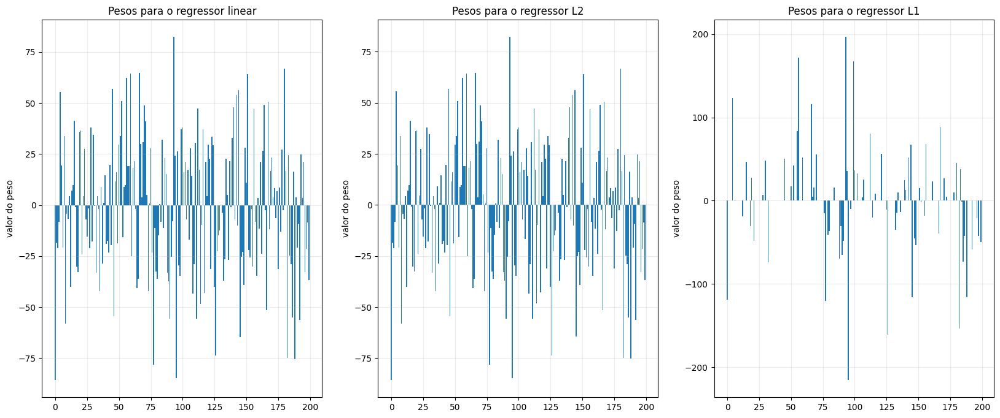

In [177]:
y_linear_pred = ols_linear.predict(X_test)
y_L2_pred = ols_L2.predict(X_test)
y_L1_pred = ols_L1.predict(X_test)

#Recuperando os coeficientes
coef_linear=ols_linear[-1].coef_
coef_L2=ols_L2[-1].coef_
coef_L1=ols_L1[-1].coef_

print("OLS: ", end="")
for i, coef in enumerate(coef_linear):
    print(rf"w{i}= {coef:.3f}, ", end="")
print()

print("Ridge: ", end="")
for i, coef in enumerate(coef_L2):
    print(rf"w{i}= {coef:.3f}, ", end="")
print()

print("Lasso: ", end="")
for i, coef in enumerate(coef_L1):
    print(rf"w{i}= {coef:.3f}, ", end="")
print()


# ---------------------------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(20, 8))

axes[0].bar(np.arange(p), coef_linear)
axes[0].grid(alpha=0.25)

axes[0].set_ylabel("valor do peso")
axes[0].set_title("Pesos para o regressor linear")

#-----------------------------------------------------------------

axes[1].bar(np.arange(p), coef_L2)
axes[1].grid(alpha=0.25)

axes[1].set_ylabel("valor do peso")
axes[1].set_title("Pesos para o regressor L2")

#-----------------------------------------------------------------

axes[2].bar(np.arange(p), coef_L1)
axes[2].grid(alpha=0.25)

axes[2].set_ylabel("valor do peso")
axes[2].set_title("Pesos para o regressor L1")
plt.show()

In [178]:
# Erro do modelo linear
MAE_linear = mean_absolute_error(y_test,y_linear_pred)
erro_coef_linear = (np.linalg.norm(coef_linear-w_true)/np.linalg.norm(w_true))
num_coef_linear= np.sum(np.abs(coef_linear)>lim)
RMSE_linear = mean_squared_error(y_test,y_linear_pred)**(1/2)
R2_linear = r2_score(y_test, y_linear_pred)

#Erro do modelo L2
MAE_L2 = mean_absolute_error(y_test,y_L2_pred)
erro_coef_L2 = (np.linalg.norm(coef_L2-w_true)/np.linalg.norm(w_true))
num_coef_L2= np.sum(np.abs(coef_L2)>lim)
RMSE_L2 = mean_squared_error(y_test,y_L2_pred)**(1/2)
R2_L2 = r2_score(y_test, y_L2_pred)

#Erro do modelo L1  
MAE_L1 = mean_absolute_error(y_test,y_L1_pred)
erro_coef_L1 = (np.linalg.norm(coef_L1-w_true)/np.linalg.norm(w_true)) 
num_coef_L1= np.sum(np.abs(coef_L1)>lim)
RMSE_L1 = mean_squared_error(y_test,y_L1_pred)**(1/2)
R2_L1 = r2_score(y_test, y_L1_pred)

print(f"Erro absoluto médio do modelo OLS: {MAE_linear:.2f}")
print(f"Erro dos coeficientes do OLS: {erro_coef_linear}")
print(f"Quantos coeficientes sobrevivem no OLS: {num_coef_linear}")
print(f"Erro quadrático médio regular do modelo OLS: {RMSE_linear:.2f}")
print(f"R² do OLS: {R2_linear:.5f}")
print("------------------------------------------------------------------")
print(f"Erro absoluto médio do modelo Ridge: {MAE_L2:.2f}")
print(f"Erro dos coeficientes do Ridge: {erro_coef_L2}")
print(f"Quantos coeficientes sobrevivem no Ridge: {num_coef_L2}")
print(f"Erro quadrático médio regular do modelo Ridge: {RMSE_L2:.2f}")
print(f"R² do Ridge: {R2_L2:.5f}")
print("------------------------------------------------------------------")
print(f"Erro absoluto médio do modelo Lasso: {MAE_L1:.2f}")
print(f"Erro dos coeficientes do Lasso: {erro_coef_L1}")
print(f"Quantos coeficientes sobrevivem no Lasso: {num_coef_L1}")
print(f"Erro quadrático médio regular do modelo Lasso: {RMSE_L1:.2f}")
print(f"R² do Lasso: {R2_L1:.5f}")

Erro absoluto médio do modelo OLS: 545.57
Erro dos coeficientes do OLS: 0.8113875444031765
Quantos coeficientes sobrevivem no OLS: 200
Erro quadrático médio regular do modelo OLS: 681.77
R² do OLS: 0.22979
------------------------------------------------------------------
Erro absoluto médio do modelo Ridge: 545.61
Erro dos coeficientes do Ridge: 0.8113876838032402
Quantos coeficientes sobrevivem no Ridge: 200
Erro quadrático médio regular do modelo Ridge: 681.78
R² do Ridge: 0.22977
------------------------------------------------------------------
Erro absoluto médio do modelo Lasso: 630.60
Erro dos coeficientes do Lasso: 1.0305739690745788
Quantos coeficientes sobrevivem no Lasso: 77
Erro quadrático médio regular do modelo Lasso: 761.88
R² do Lasso: 0.03815


Note que nesse caso, a precisão do L1 consegue ser pior que o próprio OLS. Isso é importantíssimo de se ressaltar, o modelo L1 tem consigo uma hipótese clara de esparsidade da resposta, aplicá-lo em um problema que não segue essa estrutura irá resultar em um algoritmo ruim de previsão. 

Curiosamente, o $R^2$ parece ter diminuído enormemente para os outros modelo, eles não deveriam permanecer inalterados? Quando há um número de exemplos menor que o de parâmetros, o Ridge e o LinearRegression tentam resolver o problema dentro de um subespaço do problema, este tem dimensão igual ao número de exemplos. A questão toda é, se a dimensionalidade efetiva do espaço se encaixar dentro do subespaço definido, então o hiperplano de dimensão $n$ é capaz de capturar parte dessa resposta. Então, mesmo uma solução de norma mínima, que é usado em casos sub-determinados pelo LinearRegression e pelo Ridge (que, pelo CV, usa um alpha muito pequeno), é capaz de contemplar a solução.

Contudo, para um número de parâmetros reais maior, esse espaço tem muito mais graus de liberdade. Logo, esse subespaço deixa parte da solução em um espaço nulo que é inacessível sem hipóteses adicionais, como foi o caso de assumir que a solução é esparsa.

---
### <a id='toc1_1_7_'></a>[Exemplo prático - EEG para prever tendência de movimento](#toc0_)

Antes de partirmos para o exemplo prático, desejo avisar o leitor sobre essa parte. Existem duas sessões desse desenvolvimento que não envolvem regularização nenhuma, apenas tratamento de dados e algumas discussões sobre o dataset. Por isso, caso o seu interesse seja somente a parte de Machine Learning, você poderá pular simplesmente para [Separação de dados em treino e teste](#toc1_1_7_3_), que já começa com a parte da separação dos dados. Agora, se você REALMENTE só deseja ver o modelo, você pode ir para [Modelos preditivos](#toc1_1_7_4_).

#### <a id='toc1_1_7_1_'></a>[Pegando os dados do Dataset](#toc0_)

Para iniciarmos essa seção, vamos discutir o que estamos buscando. Vamos usar um participante do dataset WAY-EEG-GAL <a id='toc0_'></a>[[9]](#toceq_9_) <a id='toc0_'></a>[[11]](#toceq_11_), essa base de dados conta com 32 canais de EEG e 5 canais de EMG <a id='toc0_'></a>[[11]](#toceq_11_). Esses dados são extremamente ruidosos e estão espalhados dentro de uma grande estrutura de dados. Antes de sequer sonharmos em extrairmos qualquer informação útil deles, precisamos separar e tratar cada um deles.

In [179]:
# pegando os arquivos

DATA_DIR = Path("data/raw/P1")
DATA_DIR.mkdir(parents=True, exist_ok=True)


ws_files = sorted(DATA_DIR.glob("WS_P1_S*.mat"))

print(f"Número de arquivos WS encontrados: {len(ws_files)}")

for arquivo in ws_files:
    print(arquivo.name)

# Converte um arquivo .mat para python puro: um dicionario
mat = loadmat(ws_files[0],simplify_cells=True)
ws=mat["ws"]
wins=ws["win"]
trial = wins[0]

eeg = trial["eeg"] #Resultado do EEG do paciente 1
# eeg_t = trial["eeg_t"]
eeg_names = ws["names"]["eeg"] #Nome de cada canal
kin_names = ws["names"]["kin"] #Nome dos sensores cinemáticos
kin = trial["kin"] #Dados cinemáticos
t = trial["eeg_t"] #Tempo de cada medida

print("Nome dos sensores do EEG:")

for i, nome in enumerate(eeg_names):
    print(i, nome, end="    ")
    if i%3==2:
        print()

Número de arquivos WS encontrados: 9
WS_P1_S1.mat
WS_P1_S2.mat
WS_P1_S3.mat
WS_P1_S4.mat
WS_P1_S5.mat
WS_P1_S6.mat
WS_P1_S7.mat
WS_P1_S8.mat
WS_P1_S9.mat
Nome dos sensores do EEG:
0 Fp1    1 Fp2    2 F7    
3 F3    4 Fz    5 F4    
6 F8    7 FC5    8 FC1    
9 FC2    10 FC6    11 T7    
12 C3    13 Cz    14 C4    
15 T8    16 TP9    17 CP5    
18 CP1    19 CP2    20 CP6    
21 TP10    22 P7    23 P3    
24 Pz    25 P4    26 P8    
27 PO9    28 O1    29 Oz    
30 O2    31 PO10    

Para usarmos esses dados, vamos fazer um caso reduzido: tentar prever a velocidade do punho no espaço. Para isso, vamos isolar o índice dos sensores de x, y e z do punho, referenciado como P4 <a id='toc0_'></a>[[11]](#toceq_11_). Esses dados descrevem a posição espacial no tempo dessa pessoa, que será particularmente útil quando tentarmos prever movimentação de uma prótese a partir de ondas cerebrais, que é uma das motivações dos autores do dataset WAY-EEG-GAL <a id='toc0_'></a>[[11]](#toceq_11_).

21 Px4 - position x sensor 4
25 Py4 - position y sensor 4
29 Pz4 - position z sensor 4


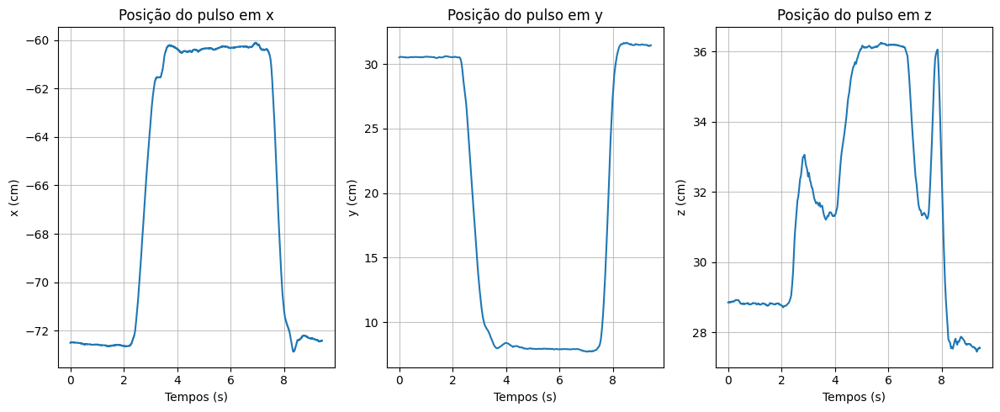

In [180]:
fig, axes = plt.subplots(1, 3, figsize=(12, 5), sharex=True)

p4_indices=[]

for i, nome in enumerate(kin_names):
    if "P" in str(nome) and "4" in str(nome):
        p4_indices.append(i)
        print(i, nome)

pulso_pos = kin[:, p4_indices]

dt=np.mean(np.diff(t))
fs=1/dt

labels=["x", "y", "z"]

for i in range(3):
    axes[i].plot(t, pulso_pos[:, i])
    axes[i].set_ylabel(f"{labels[i]} (cm)")
    axes[i].grid(alpha=0.75)
    axes[i].set_title(f"Posição do pulso em {labels[i]}")

    axes[i].set_xlabel("Tempos (s)")

plt.tight_layout()
plt.show()

Mas e a velocidade desse braço? Um jeito de achar esse valor seria dividir a variação da posição com a variação do tempo, mas isso vem com os seus próprios desafios. Digamos que o pulso quisesse permanecer parado, mas, naturalmente, ele se moveu $0.001 \ m$, com o dt sendo $0.002 \ s$ , esse simples ruido amplifica para uma velocidade de $0.5 \ \frac{m}{s}$. Por isso, espera-se que, usando esse método, o ruído do sinal fique muito alto.

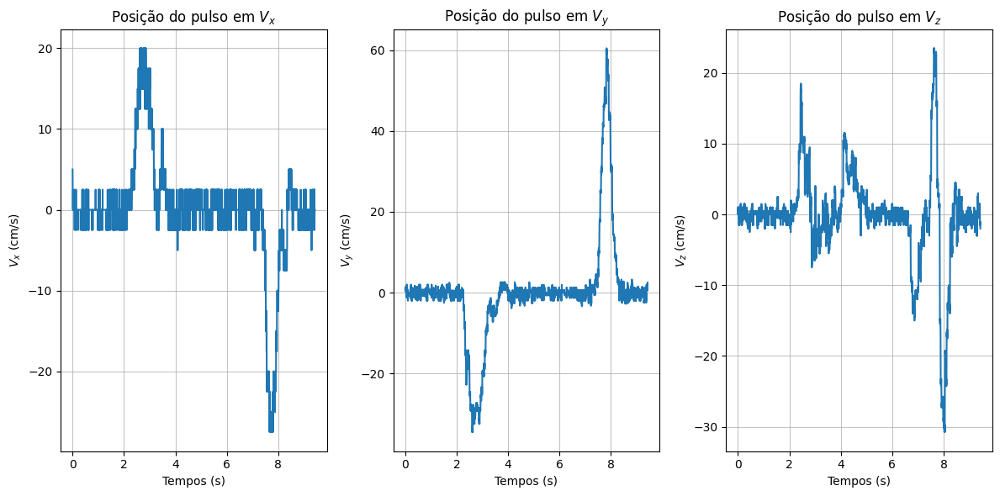

In [181]:
fig, axes = plt.subplots(1, 3, figsize=(12, 6), sharex=True)

pulso_vel = np.gradient(pulso_pos, dt, axis=0)

labels=[r"$V_x$", r"$V_y$", r"$V_z$"]

for i in range(3):
    axes[i].plot(t, pulso_vel[:, i])
    axes[i].set_ylabel(f"{labels[i]} (cm/s)")
    axes[i].grid(alpha=0.75)
    axes[i].set_title(f"Posição do pulso em {labels[i]}")

    axes[i].set_xlabel("Tempos (s)")

plt.tight_layout()
plt.show()

Para resolver isso, usaremos uma função do scipy que suaviza sinais. Isso permite tentar reduzir o ruído amplificado pela derivada.

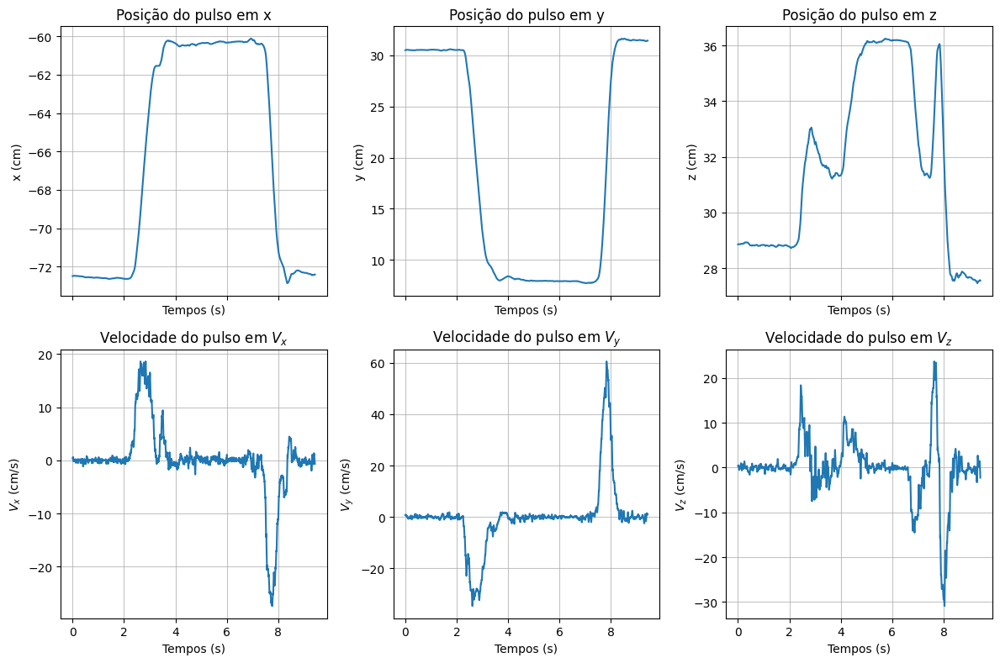

In [182]:
fig, axes = plt.subplots(2, 3, figsize=(12, 8), sharex=True)
#o window_length precisa ser impar, além disso, estamos assumindo que o movimento ocorre a cada 40 ms, ja que 21/fs da aproximadamente 40 ms
window_length = 21
polinomio_ord = 3

pulso_pos_suave = savgol_filter(pulso_pos, window_length=window_length, polyorder= polinomio_ord, axis = 0)

labels=["x", "y", "z"]

for i in range(3):
    axes[0][i].plot(t, pulso_pos_suave[:, i])
    axes[0][i].set_ylabel(f"{labels[i]} (cm)")
    axes[0][i].grid(alpha=0.75)
    axes[0][i].set_title(f"Posição do pulso em {labels[i]}")

    axes[0][i].set_xlabel("Tempos (s)")

pulso_vel_suave = np.gradient(pulso_pos_suave, dt, axis=0)

labels=[r"$V_x$", r"$V_y$", r"$V_z$"]

for i in range(3):
    axes[1][i].plot(t, pulso_vel_suave[:, i])
    axes[1][i].set_ylabel(f"{labels[i]} (cm/s)")
    axes[1][i].grid(alpha=0.75)
    axes[1][i].set_title(f"Velocidade do pulso em {labels[i]}")

    axes[1][i].set_xlabel("Tempos (s)")

plt.tight_layout()
plt.show()

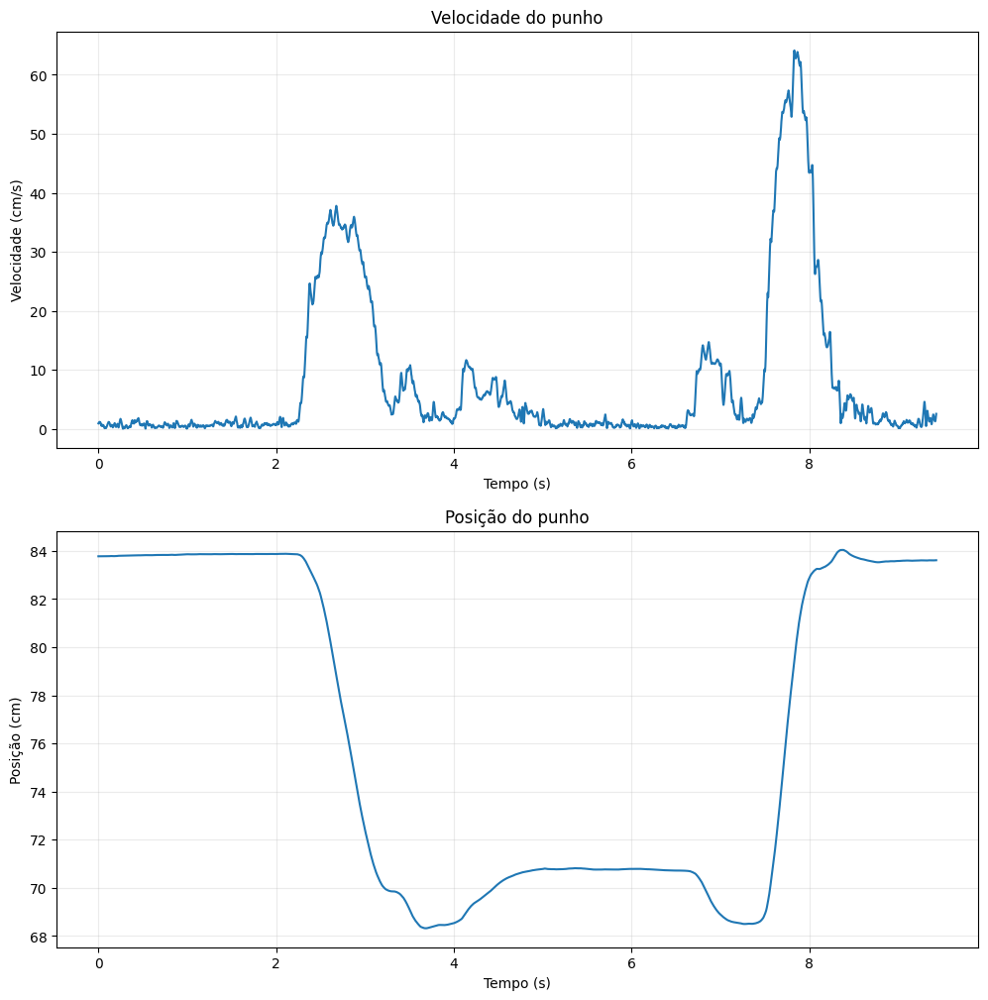

In [183]:
velocidade = np.linalg.norm(
    pulso_vel_suave,
    axis=1
)

posicao = np.linalg.norm(
    pulso_pos_suave,
    axis=1
)

fig, axes = plt.subplots(2, 1, figsize=(12, 12))

axes[0].plot(t, velocidade)

axes[0].set_xlabel("Tempo (s)")
axes[0].set_ylabel("Velocidade (cm/s)")
axes[0].set_title("Velocidade do punho")

axes[0].grid(alpha=0.25)

axes[1].plot(t, posicao)

axes[1].set_xlabel("Tempo (s)")
axes[1].set_ylabel("Posição (cm)")
axes[1].set_title("Posição do punho")

axes[1].grid(alpha=0.25)

plt.show()

#### <a id='toc1_1_7_2_'></a>[Tratando o EEG](#toc0_)

Agora, precisamos tratar o EEG para podermos usá-lo em treino e testo. Contudo, aqui que as coisas começam a dificultar. Primeiro lugar, os dados são temporalmente correlacionados, logo, pegar o ponto $e(t_i)$ para treinar o modelo e usar o $e(t_{i+1})$ para teste é incoerente. Porque? A informação que esse pontos carregam são quase que idênticas, então, o modelo teria uma acurácia incrível sem ter aprendido nada de verdade (já que estaríamos usando pontos que ele já conhece). Isso é um caso de **Data Leakage** <a id='toc0_'></a>[[1]](#toceq_1_) (isso é comentado dentro de uma célula em [Sistema Linear possível e indeterminado](#toc1_1_6_2_)) e ele é só uma das varias questões que rodeiam esse tipo de problema, cada uma será abordada quando for conveniente.

Para simplificar o problema, vamos usar somente um canal para trabalhamos. Nesse caso, o C3 é particularmente interessante, já que ele está na região onde fica o córtex sensorimotor contralateral <a id='toc0_'></a>[[11]](#toceq_11_). Não necessariamente ele terá a nossa resposta, mas é um bom casa para inspecionarmos. 

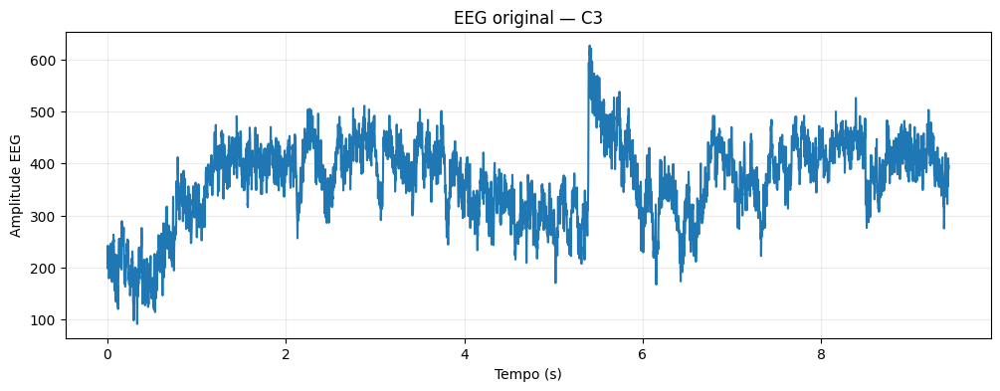

In [184]:
idx_c3 = list(eeg_names).index("C3")

plt.figure(figsize=(12, 4))

plt.plot(
    t,
    eeg[:, idx_c3]
)

plt.xlabel("Tempo (s)")
plt.ylabel("Amplitude EEG")
plt.title("EEG original — C3")
plt.grid(alpha=0.25)

plt.show()

Veja o gráfico acima e se pergunte: você consegue achar uma correlação direta com o movimento? O EEG não terá indicativos visuais claros de que existe alguma tendencia ou algo do tipo, por isso, precisamos achar um jeito de extrair essa informação dele.

Como o EEG não tem um zero absoluto, é comum usar o **Comum Average Reference (CAR)** <a id='toc0_'></a>[[12]](#toceq_12_), que tira uma média de cada um dos canais e depois subtrai esse valor dos sinais existentes.

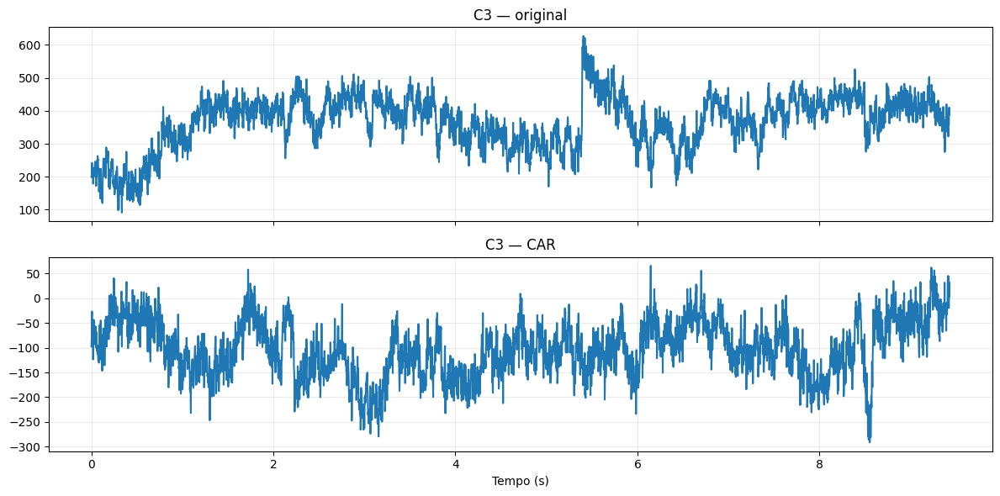

In [185]:
eeg_car = eeg - eeg.mean(axis=1, keepdims=True)

fig, axes = plt.subplots(
    2,
    1,
    figsize=(12, 6),
    sharex=True
)

axes[0].plot(
    t,
    eeg[:, idx_c3]
)

axes[0].set_title("C3 — original")
axes[0].grid(alpha=0.25)

axes[1].plot(
    t,
    eeg_car[:, idx_c3]
)

axes[1].set_title("C3 — CAR")
axes[1].set_xlabel("Tempo (s)")
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

Agora, precisamos filtrar o que buscamos para esse problema. Existe um estudo interessante que realiza exatamente o que buscamos aqui <a id='toc0_'></a>[[10]](#toceq_10_), nossa abordagem será muito baseada na dele. O estudo revela que componentes lentas do sinal são particularmente úteis para previsão de velocidade <a id='toc0_'></a>[[10]](#toceq_10_), por isso, vamos seguir o pipeline do artigo. O primeiro passo será realizar um downsampling, no momento, temos 500 amostras por segundo <a id='toc0_'></a>[[11]](#toceq_11_), e o artigo menciona que 100 Hz é suficiente <a id='toc0_'></a>[[10]](#toceq_10_). 

Entretanto, só pegar amostras de 5 em 5 seria incorreto, já que geraria erro de **aliasing** <a id='toc0_'></a>[[13]](#toceq_13_). Por isso, faremos uma reamostragem usando o resample_poly <a id='toc0_'></a>[[13]](#toceq_13_) e para diminuir a frequência usaremos a função butter <a id='toc0_'></a>[[13]](#toceq_13_) do scipy.

In [186]:
eeg_100 = resample_poly(eeg_car, up=1, down=5, axis=0)

t_100=np.arange(len(eeg_100))/100
t_100+=t[0]

sos = butter(
    N=4, #ordem do filtro
    Wn=1.0, #frequencia de 1 Hz
    btype="lowpass", #passa baixos
    fs=100, #frequencia atual
    output="sos" #uma representação numerica estavel
)



Normalmente, usaríamos sosfiltfilt <a id='toc0_'></a>[[13]](#toceq_13_) como filtro, mas ele apresenta um problema nessa prática: ele não é causal. Ele usaria dados futuros de *t* para filtrar e isso fere um pouco a tentativa de prever uma intensão (é uma previsão se já espiamos o futuro?). Por isso, vamos usar sosfilt <a id='toc0_'></a>[[13]](#toceq_13_) e sosfilt_zi <a id='toc0_'></a>[[13]](#toceq_13_) para criar um filtro causal.

In [187]:
def filtro_causal(eeg, sos):
    eeg_filtrado = np.empty_like(eeg)

    zi = sosfilt_zi(sos)

    for canal in range(eeg.shape[1]):

        sinal = eeg[:, canal]

        filtrado, _ = sosfilt(
            sos,
            sinal,
            zi=zi*sinal[0]
        )

        eeg_filtrado[:, canal]=filtrado

    return eeg_filtrado

eeg_low = filtro_causal(eeg_100, sos)

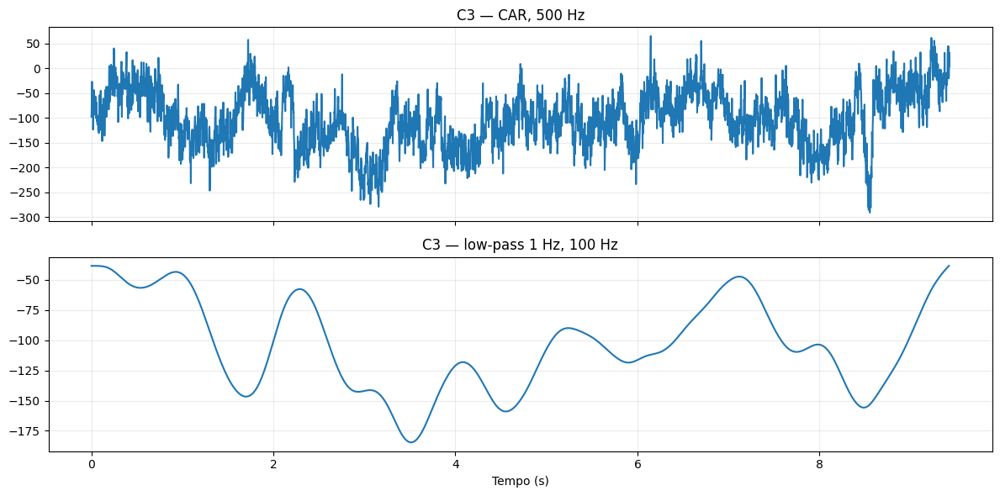

In [188]:
fig, axes = plt.subplots( 2, 1, figsize=(12, 6), sharex=True)

axes[0].plot(
    t,
    eeg_car[:, idx_c3]
)

axes[0].set_title("C3 — CAR, 500 Hz")
axes[0].grid(alpha=0.25)


axes[1].plot(
    t_100,
    eeg_low[:, idx_c3]
)

axes[1].set_title("C3 — low-pass 1 Hz, 100 Hz")
axes[1].set_xlabel("Tempo (s)")
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

Analisando os novos sinais, é possível ver uma enorme diferença. A nova variável permite analisar a dinâmica lenta do sinal, por isso tem uma forma parecida e deslocada do sinal original. 

Mas porque estudar isso? Queremos achar uma relação linear do tipo:

$$v_x(t)\approx \sum_{c=1}^{32} \sum_{k=0}^K \omega_{c,k}EEG_c(t-k)$$

Em que $c$ é o eletrodo correspondente e $k$ é o atraso temporal. Poderíamos fazer a regularização L1 ajudar a eliminar combinações específicas de $\omega_{c,k}$ para, posteriormente, aplicar L2 para ajustar a contribuição de eletrodos distintos, mas isso tornaria esse notebook muito complexo, por isso, não será feito. Isso vem de uma interpretação neurofisiológica mais profunda, da não independência das regiões do cérebro. Sabemos que não existe um local do cérebro responsável por todos os movimentos e isso conversa intrinsecamente com a natureza dos reguladores.

Obviamente, não poderemos automaticamente inferir que, se o modelo for bem sucedido, isso é uma consequência do que fizemos. O dataset não menciona que coisas como o movimento dos olhos, piscadas e outras coisas foram removidas nem tratadas. Logo, existe a chance do paciente mexer o olho toda ver que move o pulso, então, o nosso modelo pode aprender que essas interações são causais. Isso será abordado novamente mais tarde.

Antes de prosseguirmos, vamos fazer um downsampling das velocidades também.

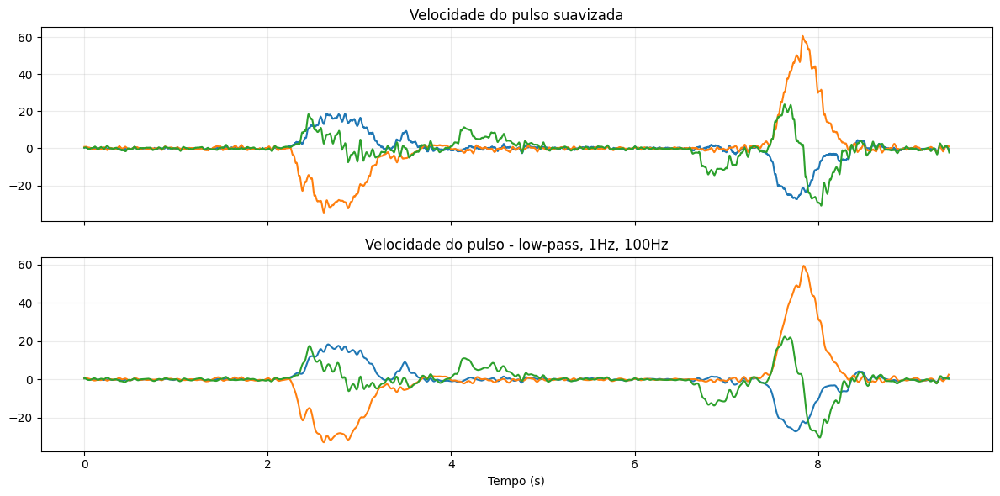

In [189]:

vel = savgol_filter(
    pulso_pos_suave,
    window_length=50,
    polyorder=3,
    deriv=1,
    delta=dt,
    axis=0
)

pulso_vel_100 = resample_poly(
vel,
up=1,
down=5,
axis=0
)

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

axes[0].plot(
    t,
    pulso_vel_suave
)

axes[0].set_title("Velocidade do pulso suavizada")
axes[0].grid(alpha=0.25)


axes[1].plot(
    t_100,
    pulso_vel_100
)

axes[1].set_title("Velocidade do pulso - low-pass, 1Hz, 100Hz")
axes[1].set_xlabel("Tempo (s)")
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()


A diferença é basicamente invisível, mas ela possibilitará com que o código funcione no futuro.

#### <a id='toc1_1_7_3_'></a>[Separação de dados em treino e teste](#toc0_)

Até agora, so tratamos os dados e discutimos a relação de $EEG(t-T, t) \to v(t+k)$, mas agora está na hora de começarmos a pensar no modelo em si. Primeiro, o que significa ele receber uma janela? No momento, temos algo do tipo:

$$
\begin{bmatrix}
C_1(t-k) & C_2(t-k) & \dots & C_n(t-k) \\
C_1(t-(k-1)) & C_2(t-(k-1)) & \dots & C_n(t-(k-1)) \\
C_1(t-(k-2)) & C_2(t-(k-2)) & \dots & C_n(t-(k-2)) \\
 \vdots & \vdots & \ddots & \vdots \\
 C_1(t) & C_2(t) & \dots & C_n(t)
\end{bmatrix}
$$

Porém, a regressão linear espera um grande vetor na forma de $[x_1,x_2, \dots, x_n]$. Por isso precisamos achatar essa matriz, isso pode ser feito alinhando cada coluna dentro do vetor. O numpy consegue fazer isso facilmente, os números que você vê a seguir são variáveis de teste, no momento, estamos chutando um valor aleatório, mas isso seria obtido empiricamente. A única variável que foi escolhida com certo pudor foi o ms_step. Lembre-se de que se o step for muito perto o sinal irá ter muita similaridade e explicar as mesmas informações, esse foi o motivo de escolhermos $50 \ ms$.

In [190]:
def cria_janela(
        eeg,
        velocidade,
        fs=100,
        ms_janela=500,
        ms_previsao=100,
        ms_step=50
):
    tamanho_janela = int(ms_janela/1000*fs)
    tamanho_previsao = int(ms_previsao/1000*fs)
    tamanho_step = int(ms_step/1000*fs)

    X=[]
    Y=[]

    primeiro_t= tamanho_janela-1
    ultimo_t= len(eeg)-tamanho_previsao

    for i in range(primeiro_t, ultimo_t, tamanho_step):
        janela = eeg[ i - tamanho_janela + 1 : i + 1].T.reshape(-1)
        target = velocidade[i+tamanho_previsao]

        X.append(janela)
        Y.append(target)

    #Vamos construir os nomes de cada canal para nos acharmos depois
    feature_names = []
    lags_ms = np.arange(
        -(tamanho_janela - 1),
        1
    ) * 1000 / fs

    for canal in eeg_names:
        for lag in lags_ms:

            feature_names.append(
                f"{canal}_{lag:.0f}ms"
            )

    return np.asarray(X), np.asarray(Y), np.asarray(feature_names)


X_trial, Y_trial, nomes_trial = cria_janela(eeg_low, pulso_vel_100)

print("X: ", X_trial.shape)
print("Y: ", Y_trial.shape)
print("Nomes: ", nomes_trial[:10])

X:  (177, 1600)
Y:  (177, 3)
Nomes:  ['Fp1_-490ms' 'Fp1_-480ms' 'Fp1_-470ms' 'Fp1_-460ms' 'Fp1_-450ms'
 'Fp1_-440ms' 'Fp1_-430ms' 'Fp1_-420ms' 'Fp1_-410ms' 'Fp1_-400ms']


Agora, antes de usarmos o train_test_split, precisamos separar as janelas em grupos. Porque? Simples, pegar janelas subsequentes para treino e teste seria contra produtivo, já que janelas consecutivas explicam informações muito parecidas. Por isso, o treino será feito em trials, em que cada trial poderá ser composto somente por treino ou teste, nunca ambos. Para isso, usaremos o GroupShuffleSplit <a id='toc0_'></a>[[14]](#toceq_14_).

In [191]:
groups_trial = np.full(len(X_trial), 0)

X= np.vstack(X_trial)
Y= np.vstack(Y_trial)

Para realmente tentar criar um modelo preditivo nesse caso, precisaríamos percorrer os arquivos do dataset e adicioná-los em blocos. Para isso, essa próxima célula será um grande apanhado do que foi feito anteriormente, para que possamos percorrer todos os arquivos.

In [192]:
def load_arquivos():

    ws = []
    wins = []

    for i in ws_files:
        mat = loadmat(i, simplify_cells=True)
        ws.append(mat["ws"])
        wins.append(mat["ws"]["win"])

    return wins, ws

def indices_vel(ws:dict):

    p4_indices = []

    for wss in ws:
        nome_kin = wss["names"]["kin"]

        p4_indices.append([i for i, nome in enumerate(nome_kin) if ("P" in str(nome) and "4" in str(nome))])

    return p4_indices

def processa_eeg(
        eeg,
        N=4,
        Wn=1.0,
        fs=100
        ):

    eeg_car = eeg - eeg.mean(axis=1, keepdims=True)
    eeg_100 = resample_poly(eeg_car, up=1, down=5, axis=0)

    sos = butter(
    N=N, #ordem do filtro 
    Wn=Wn, #frequencia de 1 Hz
    btype="lowpass", #passa baixos
    fs=fs, #frequencia atual
    output="sos" #uma representação numerica estavel
    )

    eeg_tratado = filtro_causal(eeg_100, sos)

    return eeg_tratado

def processa_vel(
        kin,
        indices,
        dt,
        polinomio_ord=3,
        window_length = 50,
        down=5
                 ):

    vel_pos_suave = savgol_filter(
        kin[:, indices], 
        window_length=window_length, 
        polyorder= polinomio_ord, 
        deriv=1, 
        delta=dt,
        axis = 0
        )
    vel_100 = resample_poly(
        vel_pos_suave,
        up=1,
        down=down,
        axis=0
    )

    return vel_100
    
    

def cria_grupos():

    X_blocos=[]
    Y_blocos=[]
    groups_blocos=[]

    trial_id=0

    wins, ws = load_arquivos()
    p4_indices = indices_vel(ws)

    for j in wins:
        for i, trial in enumerate(j):
            eeg=np.asarray(trial["eeg"], dtype=np.float32)
            kin=np.asarray(trial["kin"])
            t=np.asarray(trial["eeg_t"]).squeeze()

            dt = np.median(np.diff(t))

            eeg_processado = processa_eeg(eeg)
            vel_processada = processa_vel(kin, p4_indices[0], dt)

            N=min(len(eeg_processado), len(vel_processada))

            eeg_processado=eeg_processado[:N]
            vel_processada=vel_processada[:N]

            X_trial, Y_trial, nomes_trial = cria_janela(
                eeg_processado,
                vel_processada
            )

            groups_trial = np.full(
                len(X_trial),
                trial_id
            )

            X_blocos.append(X_trial)
            Y_blocos.append(Y_trial)
            groups_blocos.append(groups_trial)

            trial_id+=1

    return np.vstack(X_blocos), np.vstack(Y_blocos), np.concatenate(groups_blocos), nomes_trial

X, Y, grupos, nomes = cria_grupos()


print("X: ", X.shape)
print("Y: ", Y.shape)

X:  (47315, 1600)
Y:  (47315, 3)


Uma coisa interessante de cada trial é que nem todos tem o mesmo tamanho. Veja o gráfico abaixo, a grande maioria dos trials tem um tamanho entre 155 e 160. Mesmo que alguns ultrapassem, nenhum deles ultrapassou um número muito grande, isso pode simbolizar que nada de estranho aconteceu, já que o dataset descreve que tentou manter a uniformidade das medidas.

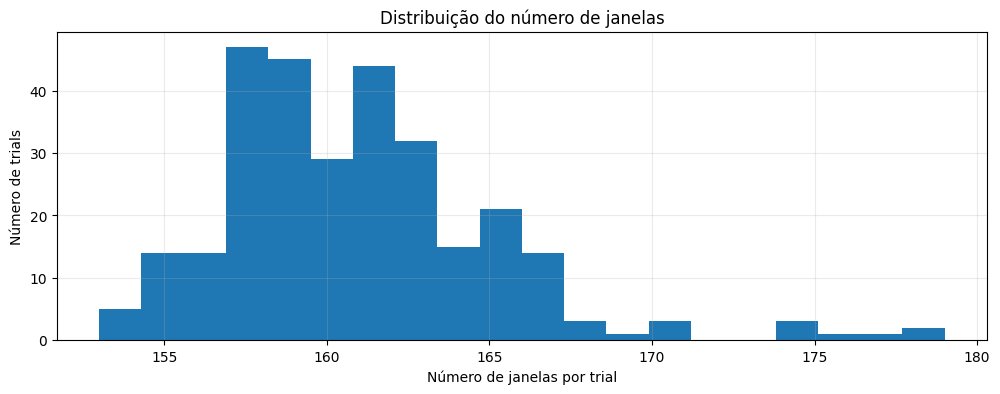

In [193]:
trial_ids, contagens = np.unique(
    grupos,
    return_counts=True
)

plt.figure(figsize=(12, 4))

plt.hist(
    contagens,
    bins=20
)

plt.xlabel("Número de janelas por trial")
plt.ylabel("Número de trials")
plt.title("Distribuição do número de janelas")

plt.grid(alpha=0.25)
plt.show()

Agora, precisamos separar o nosso trial em test e train. Porém, como comentamos antes, não podemos fazer isso com o train_test_split. Isso faria com que o modelo recebesse de teste características que ele já obteve a resposta, representando um **data_leakage**. Por isso, vamos usar o GroupShuffleSplit.

In [194]:
gss=GroupShuffleSplit(
    n_splits= 1,
    test_size=0.20,
    random_state=42
)
train_idx, test_idx = next(
    gss.split(
        X,
        Y,
        groups=grupos
    )
)

X_train = X[train_idx]
X_test = X[test_idx]

Y_train = Y[train_idx]
Y_test = Y[test_idx]

grupos_train = grupos[train_idx]
grupos_test = grupos[test_idx]

# para verificar leakage, vamos ver quando valores estao no mesmo grupo de um trial
sobreposicao = np.intersect1d(
    np.unique(grupos_train),
    np.unique(grupos_test)
)

print(sobreposicao)

[]


Essa lista vazia demonstra que a nossa forma de train_test_split conseguiu fazer uma distribuição que não tenha leakage. O que fizemos foi criar vários grupos que foram identificados como treino ou teste, mas nunca ambos. isso significa que o modelo não usa dados correlacionados temporalmente para tentar prever o movimento resultante do modelo.

#### <a id='toc1_1_7_4_'></a>[Modelos preditivos](#toc0_)

Agora, finalmente, vamos criar os modelos de leitura do EEG. Cada um tem uma lógica própria, mas todos tentam responder a mesma pergunta: **existe informação preditiva dentro de um EEG?** Não só isso, será que L1 e L2 ajudam a extrair essas informações?

Para começarmos, vamos criar os baselines para podermos comparar. O primeiro será um modelo que, para qualquer valor do EEG, sempre irá chutar que a mão está parada, já o segundo sempre chutará a média da velocidade do treino. Isso pode parecer ridículo, e até que é, mas ele é essencial para compararmos desempenho de qualquer outra coisa que faremos. Pelo dataset, a maior parte do tempo o pulso está em repouso, logo, o primeiro modelo pode ter um desempenho surpreendentemente boa, mesmo não prevendo nada. Já o segundo pode se sobressair em um trial que apresenta mais movimento. Isso define boas barreiras que o L1 e o L2 devem superar.



In [195]:
#primeiro baseline
Y_pred_base = np.zeros_like(Y_test)

#Segundo baseline
vel_media = Y_train.mean(axis=0)
Y_pred_mean = np.tile(
    vel_media,
    (len(Y_test), 1)
)

Agora, faremos uma função que fornece os erros do modelo. Vamos usar as métricas usadas anteriormente nos dois testes teóricos.

In [196]:
def avaliador_2000(Y_true, Y_pred):
    rmse = []
    mae = []
    r2 = []

    for eixo in range(3):

        rmse.append(
            mean_squared_error(Y_true[:, eixo], Y_pred[:, eixo])**0.5
        )

        mae.append(
            mean_absolute_error(Y_true[:, eixo], Y_pred[:, eixo])
        )

        r2.append(
            r2_score(Y_true[:, eixo], Y_pred[:, eixo])
        )

    erro_3d= Y_true-Y_pred

    rmse_3d = np.sqrt(
        np.mean(
            np.sum(
                erro_3d**2,
                axis=1
            )
        )
    )
    return {
        "RMSE_x": rmse[0],
        "RMSE_y": rmse[1],
        "RMSE_z": rmse[2],

        "MAE_x": mae[0],
        "MAE_y": mae[1],
        "MAE_z": mae[2],

        "R2_x": r2[0],
        "R2_y": r2[1],
        "R2_z": r2[2],

        "RMSE_3D": float(rmse_3d)
    }

erro_base = avaliador_2000(Y_test, Y_pred_base)
erro_mean = avaliador_2000(Y_test, Y_pred_mean)

print("Baseline que só chuta 0")
print()
for i in erro_base:
    print(i, erro_base[i])

print("----------------------------------------------------------------")
print("Baseline que só chuta a média")
print()
for i in erro_mean:
    print(i, erro_mean[i])

Baseline que só chuta 0

RMSE_x 9.152010667467767
RMSE_y 17.2444153919798
RMSE_z 7.4001911022172315
MAE_x 3.858986049378021
MAE_y 6.826492988363807
MAE_z 3.8628362638323575
R2_x -0.00017160204204436091
R2_y -0.000192059890476326
R2_z -6.898923401643664e-05
RMSE_3D 20.87802648283426
----------------------------------------------------------------
Baseline que só chuta a média

RMSE_x 9.151230053248806
RMSE_y 17.242769532990003
RMSE_z 7.399944785419058
MAE_x 3.878953245548323
MAE_y 6.873428041691103
MAE_z 3.865410996565414
R2_x -9.914722707282664e-07
R2_y -1.1463108717801873e-06
R2_z -2.4153608977339758e-06
RMSE_3D 20.876237579663226


Como esperado, os modelos de baseline são ruins no quesito de previsão. Analisando os gráficos da velocidade, eles tem um erro quadrático médio de aproximadamente 25% do valor máximo de cada componente e um absoluto um pouco maior do que 10%. Isso significa que, mesmo sendo extremamente idiota, o erro não está tão grande assim. Não há variações muito gritantes na posição da mão, já que as tarefas realizadas no estudo foram simples, logo, o regime médio ou de repouso é o mais frequente. 

Além disso, analisando os $R^2$, veja que ele é próximo do $0$. Isso, na realidade, é bem esperado, o baseline do $R^2$ é tirando exatamente a média, ver que ambos se aproximaram muito nos permite inferir que, provavelmente, a média é proxima de $0$, para que o primeiro modelo tivesse uma performance muito parecida com o segundo. Com isso, definimos boas métricas de desempenhos para os outros modelos.

Primeiro, o OLS simples. Vamos ver como o modelo se comporta sem nenhuma regularização

In [197]:
ols = make_pipeline(
    StandardScaler(),
    LinearRegression()
)

ols.fit(X_train, Y_train)
Y_pred_ols= ols.predict(X_test)

resultado_ols = avaliador_2000(Y_test, Y_pred_ols)

print("Modelo OLS")
print()
for i in resultado_ols:
    print(i, resultado_ols[i])

Modelo OLS

RMSE_x 7.390743718293756
RMSE_y 14.099833369402553
RMSE_z 6.663813564624676
MAE_x 5.080020185167589
MAE_y 9.439511963528004
MAE_z 4.3599653893047075
R2_x 0.3477444698309713
R2_y 0.33132603926058857
R2_z 0.18905805037897028
RMSE_3D 17.257891093018642


Analisando suas estatísticas, veja que o modelo do OLS ainda tem um erro alto, mas já é uma melhora impressionante principalmente pela simplicidade. Ele ainda contém um erro alto, com o RMSE atingindo $28%$ do total e o MAE atingindo $11%$ desse mesmo máximo. Isso pode parecer incrivel a primeira vista, como um dos modelos mais básicos conseguiu uma previsão relativamente boa somente com um simples fit? Devemos lembrar que estamos lidando com $47315$ exemplos de EEG, o OLS se beneficia de dataset muito grandes e como, nesse caso, temos mais exemplos do que parâmetros, o OLS tem a possibilidade se ajustar bem. Por isso, OLS tende a estabilizar quando temos dados demais, dando resultados interessantes para esse tipo de caso. 

Contudo, não confunda. O OLS é melhor que os baselines, mas ele ainda não se aproxima do bom. Ter um erro de $28%$, por exemplo, pode resultar em uma divergência enorme em poucos passo. Pense que temos incerteza de até um quarto da medida, logo, se a velocidade do pulso é $10 \ \frac{cm}{s}$, não temos certeza nem da casa da unidade, acima de $40 \ \frac{cm}{s}$ já não podemos garantir a casa da dezena.

Por isso, é extremamente importante entender o seu problema, não só para tratar corretamente os dados, mas para saber quando algo pode ou não pode resolver o problema. Nesse caso, usar regressão linear sem nenhuma hipótese era quase que um caso condenado ao fracasso.

Antes de partirmos para as regularizações, porque não fazemos uma hipótese sobre os dados? Podemos usar CrossValidation de forma independente em três modelos distintos para prever o melhor hiperparâmetro de cada eixo. Assim, assumimos o seguinte:

**E se as dificuldade de previsão de um eixo não se traduzem na previsão dos outros?**

Isso permite buscarmos um modelo que prevê por eixo, infelizmente o OLS não tem hiperparâmetros para ajustar por eixos, por isso, não poderemos aplicar essa hipótese nele.

In [198]:
def busca_modelo_eixo_CV(
        modelo,
        param_grid,
        X_train,
        Y_train,
        grupos_train,
        cv
):

    buscas = []
    mse = []

    cv_folds = list(cv.split(X_train, groups=grupos_train))

    for eixo in range(3):

        minimo=[float("inf"), 0]

        if modelo =="L1":
            for i, alpha in enumerate(param_grid["lasso__alpha"]):

                print(f"\r{100*(i)/len(param_grid["lasso__alpha"]):.2f} %", end="")

                busca = make_pipeline(
                    StandardScaler(),
                    Lasso(
                            alpha= alpha,
                            max_iter=3000,
                            tol=1e-3,
                            warm_start=True,
                            selection= "random",
                            random_state=42
                            )
                        )
                
                scores = cross_val_score(
                    busca,
                    X_train,
                    Y_train[:, eixo],
                    n_jobs=-1,
                    cv=cv_folds,
                    scoring="neg_mean_squared_error"
                    )

                if -scores.mean()<minimo[0]:
                    minimo[0]=-scores.mean()
                    minimo[1]=busca

                
                mse.append(-scores.mean())


        else:
            for i, alpha in enumerate(param_grid["ridge__alpha"]):

                print(f"\r{100*(i)/len(param_grid["ridge__alpha"]):.2f} %", end="")

                busca = make_pipeline(
                    StandardScaler(),
                    Ridge(
                            alpha= alpha,
                            max_iter=3000,
                            solver="lsqr",
                            random_state=42
                            )
                        )

                scores = cross_val_score(
                    busca,
                    X_train,
                    Y_train[:, eixo],
                    n_jobs=-1,
                    cv=cv_folds,
                    scoring="neg_mean_squared_error"
                    )

                if -scores.mean()<minimo[0]:
                    minimo[0]=-scores.mean()
                    minimo[1]=busca
                
                
                mse.append(-scores.mean())

        print("\r100 %", end="\n")

        minimo[1] = minimo[1].fit(X_train, Y_train[:, eixo])
        busca = minimo[1]

        buscas.append(busca)

    return buscas, mse

Agora, partimos para a regularização L2. Aqui partimos para uma hipótese interessante, estamos supondo que os eletrodos tem várias informações redundantes e que a resposta está em permitir que cada um contribua com a resposta. Como faremos o CV na mão dessa vez, vamos usar o <span style="color:#97E1F1">Ridge</span>() e o <span style="color:#97E1F1">Lasso</span>(). Os parâmetros obtidos nesse caso serão discutidos posteriormente.

In [199]:
ridge = "L2"

alphas_ridge = np.logspace(
    2,
    3,
    30
)
ridge_grid = {
    "ridge__alpha": alphas_ridge
}
gkf = GroupKFold(n_splits=3)

ridge_busca, ridge_score = busca_modelo_eixo_CV(
    ridge,
    ridge_grid,
    X_train,
    Y_train,
    grupos_train,
    cv=gkf
)

Y_pred_ridge = np.column_stack([
    busca.predict(X_test) for busca in ridge_busca
])



100 % %
100 % %
100 % %


Agora que o modelo está treinado, vamos conferir os $\lambda$'s usados.

In [200]:
nomes_eixos = ["x", "y", "z"]

for eixo, busca in zip(
    nomes_eixos,
    ridge_busca
):

    print(
        eixo,
        busca[-1].alpha
    )

x 161.02620275609394
y 188.73918221350976
z 188.73918221350976


Algo interessante de se notar, cada eixo pareceu precisar de um $\lambda$ diferente. Isso não comprova, mas é um indicio interessante de que, para encontrar o modelo que melhor prevê, ele julgou que a melhor abordagem é aumentar a regularização em alguns eixos e diminuir nos outros.

Mesmo com essa diferença, ainda sim os valores são muito parecidos. Isso era levemente esperado, não parece ter alguma preferência por movimento em algum eixo, então, ver que a hipótese dos eixos independentes se mostrou uma preferência real é uma surpresa. Contudo, será que esse realmente é o melhor caminho? Vamos ver em relação ao Ridge sem diferenciação axial.

In [201]:
resultado_ridge = avaliador_2000(Y_test, Y_pred_ridge)

print("Resultados Ridge (eixos diferenciados)")
print()
for i in resultado_ridge:
    print(i, resultado_ridge[i])

print("-----------------------------------------------")


gkf = GroupKFold(n_splits=3)
cv_folds = list(gkf.split(X_train, groups=grupos_train))

ridge_se = make_pipeline(
    StandardScaler(),
    RidgeCV(
        alphas=alphas_ridge,
        cv=cv_folds
    )
)

ridge_se.fit(X_train, Y_train)
Y_pred_ridge_se = ridge_se.predict(X_test)

resultado_ridge_se = avaliador_2000(Y_test, Y_pred_ridge_se)
print("Resultados Ridge (eixos não diferenciados)")
print()
for i in resultado_ridge_se:
    print(i, resultado_ridge_se[i])

Resultados Ridge (eixos diferenciados)

RMSE_x 7.872509375165766
RMSE_y 15.013575708454308
RMSE_z 6.974713303727939
MAE_x 4.965117393040927
MAE_y 9.145763501291185
MAE_z 4.263578756889756
R2_x 0.2599384224907385
R2_y 0.2418507188040716
R2_z 0.11162401159594959
RMSE_3D 18.331134309822776
-----------------------------------------------
Resultados Ridge (eixos não diferenciados)

RMSE_x 7.863539579791761
RMSE_y 14.987137271342107
RMSE_z 6.964945963375572
MAE_x 4.942918976771473
MAE_y 9.123380295425184
MAE_z 4.251407955027601
R2_x 0.2616238874104949
R2_y 0.24451852210484704
R2_z 0.11411042060148469
RMSE_3D 18.30191275757113


Aqui podemos comparar o modelo com e sem a diferenciação de eixos. Note que o desempenho entre eles não muda muito um em relação ao outro, podemos usar o erro 3D para falar que o modelo de eixos não diferenciados erra um pouco menos, mas isso não é gritante o suficiente para afirmar que um é melhor que o outro. Em geral, o modelo é pior que o OLS, mas existe uma discussão a ser feita nesse quesito. Guardaremos ela para a sessão final desse notebook.

Enfim, vamos para a regularização L1. Agora iremos idealizar a seguinte hipótese: e se poucas janelas temporais dos eletrodos são necessários para explicar o movimento do pulso? Ou seja, a representação do movimento é esparsa no espaço canal-tempo? Pensar nisso é idealizar que as regiões que são responsáveis pelo fenômeno do movimento do pulso são bem definidas e que os outros sinais pegam apenas resíduos dessa região. Logo, para explicar esse movimento, não seria necessário considerar todos os canais, apenas alguns.

In [202]:
lasso = "L1"

alphas_lasso = np.logspace(
    -3,
    -1,
    8
)[::-1]
lasso_grid={
    "lasso__alpha":alphas_lasso
}

gkf = GroupKFold(n_splits=3)

lasso_busca, lasso_score = busca_modelo_eixo_CV(
    lasso,
    lasso_grid,
    X_train,
    Y_train,
    grupos_train,
    cv=gkf
)

Y_pred_lasso = np.column_stack([
    busca.predict(X_test) for busca in lasso_busca
])

100 % %


C:\Users\vinicius2610042\AppData\Roaming\Python\Python313\site-packages\sklearn\linear_model\_coordinate_descent.py:840: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 5.921900e+04, tolerance: 3.144e+03
  model = cd_fast.enet_coordinate_descent(


100 % %


C:\Users\vinicius2610042\AppData\Roaming\Python\Python313\site-packages\sklearn\linear_model\_coordinate_descent.py:840: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 6.013600e+04, tolerance: 1.074e+04
  model = cd_fast.enet_coordinate_descent(


100 % %


C:\Users\vinicius2610042\AppData\Roaming\Python\Python313\site-packages\sklearn\linear_model\_coordinate_descent.py:840: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 5.319656e+04, tolerance: 2.113e+03
  model = cd_fast.enet_coordinate_descent(


Só um adendo antes de entrarmos nos resultados do Lasso, o <span style="color:#97E1F1">LassoCV</span>() não consegue regularizar mais de um target ao mesmo tempo. Para isso, usaremos o <span style="color:#97E1F1">MultiTaskLassoCV</span>(), que penaliza não só os três eixos ao mesmo tempo mas também favorece que features sejam eliminadas entre os três targets. 

In [203]:
resultado_lasso = avaliador_2000(Y_test, Y_pred_lasso)

print("Resultados Lasso (eixos diferenciados)")
print()
for i in resultado_lasso:
    print(i, resultado_lasso[i])

print("-------------------------------------------------")

gkf = GroupKFold(n_splits=3)
cv_folds = list(gkf.split(X_train, groups=grupos_train))

lasso_se = make_pipeline(
    StandardScaler(),
    MultiTaskLassoCV(
        alphas=alphas_lasso,
        cv=cv_folds,
        max_iter=3000,
        tol=1e-3,
        selection="random",
        random_state=42,
        n_jobs=-1
    )
)

lasso_se.fit(X_train, Y_train)
Y_pred_lasso_se = lasso_se.predict(X_test)

resultado_lasso_se = avaliador_2000(Y_test, Y_pred_lasso_se)
print("Resultados Lasso (eixos não diferenciados)")
print()
for i in resultado_lasso_se:
    print(i, resultado_lasso_se[i])

Resultados Lasso (eixos diferenciados)

RMSE_x 7.854833362893741
RMSE_y 14.999358534084688
RMSE_z 6.954900546321929
MAE_x 4.892086658059866
MAE_y 9.013650587810451
MAE_z 4.231552937034929
R2_x 0.2632579871302616
R2_y 0.2432859048316095
R2_z 0.1166639832011176
RMSE_3D 18.304365741595003
-------------------------------------------------


C:\Users\vinicius2610042\AppData\Roaming\Python\Python313\site-packages\sklearn\linear_model\_coordinate_descent.py:802: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 5.065400e+04, tolerance: 1.057e+04
  model = cd_fast.enet_coordinate_descent_multi_task(
C:\Users\vinicius2610042\AppData\Roaming\Python\Python313\site-packages\sklearn\linear_model\_coordinate_descent.py:802: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.256675e+04, tolerance: 1.064e+04
  model = cd_fast.enet_coordinate_descent_multi_task(
C:\Users\vinicius2610042\AppData\Roaming\Python\Python313\site-packages\sklearn\linear_model\_coordinate_descent.py:802: ConvergenceWarning: Objective did not converge. You might want to increase the number of 

Resultados Lasso (eixos não diferenciados)

RMSE_x 7.848058115116242
RMSE_y 14.95642646800156
RMSE_z 7.015711693447893
MAE_x 4.901228404002209
MAE_y 9.024146132010095
MAE_z 4.217838489929802
R2_x 0.2645284041280108
R2_y 0.24761153061284447
R2_z 0.10114930667557076
RMSE_3D 18.289530323017075


C:\Users\vinicius2610042\AppData\Roaming\Python\Python313\site-packages\sklearn\linear_model\_coordinate_descent.py:2833: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.723565e+05, tolerance: 1.600e+04
  ) = cd_fast.enet_coordinate_descent_multi_task(


Para facilitar a visualização e comparação dos modelos, veja a tabela abaixo. 

In [204]:
resultados = pd.DataFrame({
    "Zero": erro_base,
    "Média": erro_mean,
    "OLS": resultado_ols,
    "Ridge": resultado_ridge,
    "Ridge (sem diferenciação de eixos)": resultado_ridge_se,
    "Lasso": resultado_lasso,
    "Lasso (sem diferenciação de eixos)": resultado_lasso_se,
}).T

resultados

,RMSE_x,RMSE_y,RMSE_z,MAE_x,MAE_y,MAE_z,R2_x,R2_y,R2_z,RMSE_3D
Zero,9.152011,17.244415,7.400191,3.858986,6.826493,3.862836,-1.716020e-04,-0.000192,-0.000069,20.878026
Média,9.151230,17.242770,7.399945,3.878953,6.873428,3.865411,-9.914723e-07,-0.000001,-0.000002,20.876238
OLS,7.390744,14.099833,6.663814,5.080020,9.439512,4.359965,3.477445e-01,0.331326,0.189058,17.257891
Ridge,7.872509,15.013576,6.974713,4.965117,9.145764,4.263579,2.599384e-01,0.241851,0.111624,18.331134
Ridge (sem diferenciação de eixos),7.863540,14.987137,6.964946,4.942919,9.123380,4.251408,2.616239e-01,0.244519,0.114110,18.301913
Lasso,7.854833,14.999359,6.954901,4.892087,9.013651,4.231553,2.632580e-01,0.243286,0.116664,18.304366
Lasso (sem diferenciação de eixos),7.848058,14.956426,7.015712,4.901228,9.024146,4.217838,2.645284e-01,0.247612,0.101149,18.289530


Em geral, nenhum modelo foi muito bom. Todos apresentaram suas dificuldades e, analisando pelo $R^2$, o OLS foi o que obteve o melhor desempenho. Mesmo assim, sua melhor componente teve um erro quadrático $35 %$ menor que o baseline do $R^2$. Isso parece ser algo decepcionante, então, no final das contas, o melhor modelo era o que simplesmente não regularizava?

Antes de qualquer coisa, vamos analisar os $\lambda$'s encontrados.

In [205]:
print("Para o Ridge \n")
for eixo, busca in zip(
    ["x", "y", "z"],
    ridge_busca
):
    print(eixo, ":", busca[-1].alpha)

print("\n ------------------------------------------------- \n")

print("Para o Lasso \n")

for eixo, busca in zip(
    ["x", "y", "z"],
    lasso_busca
):
    print(eixo, ":", busca[-1].alpha)

Para o Ridge 

x : 161.02620275609394
y : 188.73918221350976
z : 188.73918221350976

 ------------------------------------------------- 

Para o Lasso 

x : 0.0071968567300115215
y : 0.013894954943731374
z : 0.003727593720314938


E para os coeficientes:

In [206]:
print("Para o Ridge:\n")

for eixo, busca in zip(
    ["x", "y", "z"],
    ridge_busca
):
    print(eixo, ":", busca[-1].coef_)

print("--------------------------------------------")

print("Para o Lasso:\n")

for eixo, busca in zip(
    ["x", "y", "z"],
    lasso_busca
):
    print(eixo, ":", busca[-1].coef_)

Para o Ridge:

x : [ 0.7295226   0.60385907  0.48721266 ... -1.0787696  -1.1629007
 -1.2281816 ]
y : [-1.3243114 -1.0950757 -0.8841398 ...  1.8856027  2.084839   2.2639222]
z : [ 0.00712469 -0.00165222 -0.00947303 ...  0.04601594  0.00321438
 -0.05255557]
--------------------------------------------
Para o Lasso:

x : [ 0.46024507  0.          0.         ... -0.         -0.9247498
 -2.1234834 ]
y : [-0.8363647 -0.        -0.        ...  0.         0.5326367  4.0411234]
z : [-0.         -0.         -0.         ...  0.33690915  0.1851606
  0.02788827]


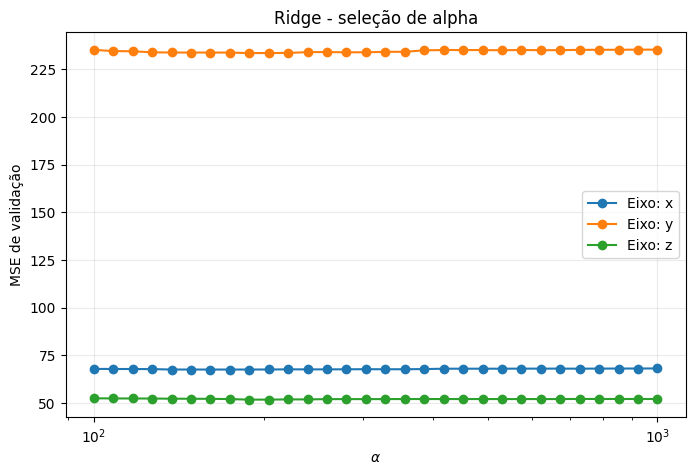

In [207]:
results = ridge_busca
alphas = alphas_ridge
mse = ridge_score

plt.figure(figsize=(8, 5))

eixos=["x", "y", "z"]
tam = len(alphas)

for i in range(3):
    plt.semilogx(
        alphas,
        mse[i*tam:(i+1)*tam],
        marker="o",
        label=f"Eixo: {eixos[i%3]}"
    )

plt.xlabel(r"$\alpha$")
plt.ylabel("MSE de validação")
plt.title("Ridge - seleção de alpha")

plt.grid(alpha=0.25)
plt.legend()

plt.show()

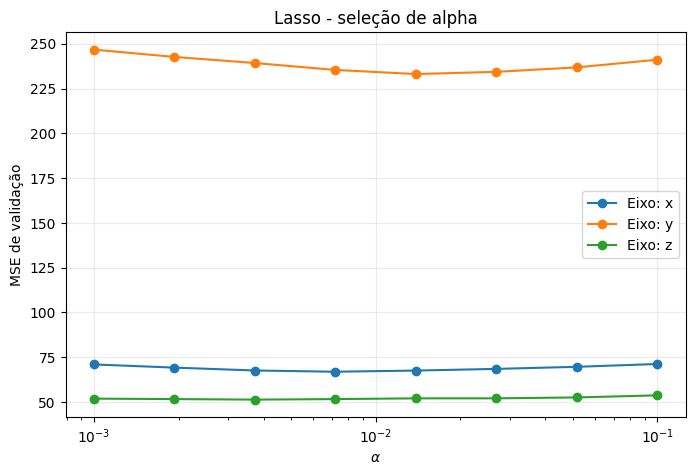

In [208]:
results = lasso_busca
alphas = alphas_lasso
mse = lasso_score

plt.figure(figsize=(8, 5))

eixos=["x", "y", "z"]
tam = len(alphas)

for i in range(3):
    plt.semilogx(
        alphas,
        mse[i*tam:(i+1)*tam],
        marker="o",
        label=f"Eixo: {eixos[i%3]}"
    )

plt.xlabel(r"$\alpha$")
plt.ylabel("MSE de validação")
plt.title("Lasso - seleção de alpha")

plt.grid(alpha=0.25)
plt.legend()

plt.show()

Veja que, para o caso do Lasso, o melhor alpha ainda não foi encontrado (como eles deram o menor valor do intervalo, a suspeita é clara). Mesmo assim, isso provavelmente não irá melhorar muito mais o modelo, mas porque as regularizações foram piores que o OLS? Isso não é uma conclusão absoluta, mesmo o $R^2$ tendo sido visivelmente pior, o MAE não seguiu essa tendencia. Em relação ao $R^2$ ou o RMSE, temos a seguinte ordem:

$${OLS}_{R^2}>{Ridge}_{R^2}\approx {Lasso}_{R^2}$$

$${Ridge}_{RMSE}\approx {Lasso}_{RMSE}>{OLS}_{RMSE}$$

Contudo, ao colocarmos em ordem do MAE, temos:

$${OLS}_{MAE}>{Ridge}_{MAE}>{Lasso}_{MAE}$$

O que isso significa? Mesmo que o desempenho do OLS ultrapasse os outros dois modelos, ele ainda perde quando analisamos na métrica de erro absoluto. Isso mostra que o OLS está mais adaptado para reduzir o RMSE, mas as regularizações conseguiram diminuir mais o MAE. Isso demonstra capacidades diferentes de cada modelo, talvez um MAE menor simbolize erros mais polarizados do que distribuídos e isso seja exatamente o que você busca. A questão é: não podemos bater o pé tão fortemente que um é superior ao outro somente pelo $R^2$, já que os erros são quase idênticos.

Mesmo assim,também não podemos simplesmente ignorar o fato do OLS ter um desempenho superior que os outros modelos, talvez, a resposta seja a mais anticlimática: a regularização feita simplesmente não é boa no problema que estávamos tentando resolver. Sabemos que o OLS se favoreceu com o volume de dados, quem sabe ele fosse a ferramenta certa para resolver isso? Não podemos nos prender a algoritmos e modelos que não funcionam em um dado problema, aceitar a derrota e estudar o motivo da falha. Uma teoria do autor para isso é a utilização individual dessas regularizações. Existe um modelo de regularização que mistura o Ridge com o Lasso chamado ElasticNet <a id='toc0_'></a>[[1]](#toceq_1_), mas ele não será abordado pela extensão atual do notebook.

Outro ponto interessante para se discutir é a tentativa de criar grupos independentes para cada eixo. Analisando a capacidade preditiva, parece que houve uma perda ínfima por separar os eixos, mas existe um ganho em um lugar talvez inesperado: tempo. Mesmo que só usar o <span style="color:#97E1F1">LassoCV</span>() de resultados melhores, o tempo de treino entre o com separação de eixos foi quase metade do que não separava. O <span style="color:#97E1F1">RidgeCV</span>() teve um tempo menor por ter uma solução fixa, então ele pode ser declarado como um que não teve ganho substancial pela separação dos eixos. Entretanto, podemos apontar o fato do nosso Lasso que separava os eixos ainda não encontrou os melhores $\lambda$'s para a demora maior do outro, o Lasso é um modelo que demora muito para convergir quando menor essa variável, então, quem sabe, o motivo dessa diferença de tempo foi o uso de um $\lambda$ maior.

Ademais, veja os coeficientes do Lasso, note que vários deles zeraram. Isso simboliza que muitos resultados o Lasso julgou que não valia a pena manter as características, talvez, o resultado que o OLS encontrou foi um chute que se adéqua aos dados (como vimos em [Valor de casas em terrenos](#toc1_1_6_1_)), mas que não é tão bem interpretável, se for. No entanto, veja esses resultados como preliminares, já que, como o leitor já deve ter notado, avisos de ConvergenceWarning foram emitidos nos treinamentos do Lasso.

Lembre-mos que se esse fosse um problema que pudesse ser simplesmente resolvido com uma ou outra regularização já teríamos uma tecnologia inimaginavelmente avançada nessa área. Por isso, finalizo esse notebook enunciando: antes de aprender a matemática e como aplicar a técnica, entenda suas limitações e o que ela busca.

In [210]:
fig, axes = plt.subplots(4,1, figsize=(28, 24), dpi=1000)

fig.suptitle('Velocidades previstas por cada modelo', fontsize=32)

espaco = np.linspace(0, X_test.shape[0]-1, X_test.shape[0])

axes[0].plot(espaco, Y_pred_ols[:,0], label="Previsão OLS", linestyle="--")
axes[0].plot(espaco, Y_pred_lasso[:,0], label="Previsão Lasso", linestyle="-.")
axes[0].plot(espaco, Y_pred_ridge[:,0], label="Previsão Ridge", linestyle=":")
axes[0].plot(espaco, Y_test[:,0], label="Dados reais")

axes[0].set_ylabel(r"Velocidade ($\frac{cm}{s}$)")
axes[0].set_xlabel(r"Amostras do conjunto de teste")
axes[0].set_title("Velocidade no eixo x")

axes[0].legend()
axes[0].grid(alpha=0.75)

axes[1].plot(espaco, Y_pred_ols[:,1], label="Previsão OLS", linestyle="--")
axes[1].plot(espaco, Y_pred_lasso[:,1], label="Previsão Lasso", linestyle="-.")
axes[1].plot(espaco, Y_pred_ridge[:,1], label="Previsão Ridge", linestyle=":")
axes[1].plot(espaco, Y_test[:,1], label="Dados reais")

axes[1].set_ylabel(r"Velocidade ($\frac{cm}{s}$)")
axes[1].set_xlabel(r"Amostras do conjunto de teste")
axes[1].set_title("Velocidade no eixo y")

axes[1].legend()
axes[1].grid(alpha=0.75)

axes[2].plot(espaco, Y_pred_ols[:,2], label="Previsão OLS", linestyle="--")
axes[2].plot(espaco, Y_pred_lasso[:,2], label="Previsão Lasso", linestyle="-.")
axes[2].plot(espaco, Y_pred_ridge[:,2], label="Previsão Ridge", linestyle=":")
axes[2].plot(espaco, Y_test[:,2], label="Dados reais")

axes[2].set_ylabel(r"Velocidade ($\frac{cm}{s}$)")
axes[2].set_xlabel(r"Amostras do conjunto de teste")
axes[2].set_title("Velocidade no eixo z")

axes[2].legend()
axes[2].grid(alpha=0.75)

def load_arquivos():

    ws = []
    wins = []

    for i in ws_files[:1]:
        mat = loadmat(i, simplify_cells=True)
        ws.append(mat["ws"])
        wins.append(mat["ws"]["win"])

    return wins, ws

X, Y, _, _ = cria_grupos()

Y = np.linalg.norm(
    Y,
    axis=1
)


Y_trial_ols = np.linalg.norm(
    ols.predict(X),
    axis=1
)

Y_trial_ridge = np.column_stack([
    busca.predict(X) for busca in ridge_busca
])
Y_trial_ridge=np.linalg.norm(
    Y_trial_ridge,
    axis=1
)

Y_trial_lasso = np.column_stack([
    busca.predict(X) for busca in lasso_busca
])
Y_trial_lasso=np.linalg.norm(
    Y_trial_lasso,
    axis=1
)


espaco = np.linspace(0, Y.shape[0]-1, Y.shape[0])

axes[3].plot(espaco, Y_trial_ols, label="Previsão OLS", linestyle="--")
axes[3].plot(espaco, Y_trial_lasso, label="Previsão Lasso", linestyle="-.")
axes[3].plot(espaco, Y_trial_ridge, label="Previsão Ridge", linestyle=":")
axes[3].plot(espaco, Y, label="Dados reais")

axes[3].set_ylabel(r"Velocidade ($\frac{cm}{s}$)")
axes[3].set_xlabel(r"Amostras do conjunto de teste")
axes[3].set_title("Velocidade do trial 1")

axes[3].legend()
axes[3].grid(alpha=0.75)

plt.show()

Antes de iniciarmos a análise, saiba que os gráficos dos modelos está levemente deslocado da sua posição real. Isso ocorreu pois a previsão era para ser $100 \ ms$ a frente do EEG naquele tempo, mas o gráfico plota ambos como se esse atraso não existisse. Peço um pouco de criatividade do leitor de imaginar que as linhas estão levemente deslocadas para a esquerda.

Para finalizarmos essa tarefa, decidi mostrar um último gráfico. Esse gráfico mostra como, a partir do mesmo EEG, cada modelo prevê a velocidade do pulso. Note que as previsões até tem um padrão, mas nenhuma delas chega perto de acertar. O OLS tem muitos mais picos que os outros modelos, parecendo que ele tenta chutar mais onde tem a intenção de movimento. Já o Ridge e o Lasso ficaram muito parecidos, eles parecem ser mais tímidos nos seus chutes, tendo boas estimativas de onde há o movimento mas sempre chutando uma intensidade baixa.

Ademais, podemos ver aqui um possível motivo do porque o RMSE do OLS foi melhor que os outros modelos enquanto ele perdia no quesito do MAE. Parece que o OLS tem mais chutes fora do estado de equilíbrio (onde $V_{pulso}\approx 0$), porém esses erros não penalizam tanto no RMSE já que são pequenos. Entretanto, a sua estimativa permite chutar valores mais altos quando há um pico real, diminuindo a distância e, por consequência, penalizando muito menos o RMSE. Então, o OLS prevê com uma certa inacurácia inata, mas algumas previsões são relativamente boas, o que diminui o seu RMSE e aumenta o seu MAE.

Obviamente, isso é uma analise visual, existe uma clara limitação no que pode ser extraído visualmente sem aplicarmos alguma analise gráfica. Então o que estamos esperando? Vamos aplicá-las!

...

Será que é necessário? Acredito que já estamos extensos demais até o momento, e pelo que? Conseguir uma ou duas conclusões a mais de algo que já observamos? Deixo aqui essa tarefa ao leitor, acredito que esse seja o fim.

Agradeço imensamente a sua atenção, caro leitor. Espero que esse trabalho tenha conseguido te mostrar o potencial e as limitações da regularização L1 e L2. Qualquer dúvida, basta me contatar pelo email: vinicutolo@gmail.com.

Por fim, caso queira ampliar a sua visão, só há um modo de fazê-la: [clique aqui](https://www.youtube.com/watch?v=dQw4w9WgXcQ)

### <a id='toc1_1_8_'></a>[Apêndice](#toc0_)

<a id='tocap_1_'></a>[{1}](#toc0_) Subgradiente, em resumo, é uma ferramenta matemática especifica do ramo de otimização convexa. Imagine que tenhamos um ponto que não apresenta derivada direcional, para podermos continuar com o código e gerar formas de otimização desse tipo de função, dizemos que o gradiente daquele ponto está em um intervalo que respeite a convexidade daquele ponto. Por isso, subgradiente é uma generalização da derivada comum para pontos não suaves.

<a id='tocap_2_'></a>[{2}](#toc0_) A decomposição SVD é um método numérico importante da algebra linear que decompõe qualquer matriz, real ou complexa. Essa técnica transforma a matriz original em três outras: U, $\Sigma$ e $V^T$. Em especial, essas matrizes tem os seus valores singulares explícitos, o que da muita informação sobre a matriz/sistema original.

<a id='tocap_3_'></a>[{3}](#toc0_) Podemos estimar esse valor usando a área urbanizada residencial do Brasil e o número de domicílios. Usando o valor de $53.925 \ km^2$ de área domiciliar [7] e e de que há $79,3$ milhões de casas no Brasil [8], podemos dividir esses valores para estimar que o valor médio do terreno no Brasil é de $680 \ m^2$. Obviamente, isso é uma estimativa extremamente grosseira, mas serve para os propósitos do notebook.  

### <a id='toc1_1_9_'></a>[Referências](#toc0_)

<a id='toceq_1_'></a>[[1]](#toc0_) JAMES, Gareth; WITTEN, Daniela; HASTIE, Trevor; et al. An Introduction to
Statistical Learning: with Applications in Python. 2023. Disponível em:
https://www.statlearning.com

<a id='toceq_2_'></a>[[2]](#toc0_) FACELI, Katti; LORENA, AC; GAMA, João; et al. Inteligência Artificial: uma abordagem de Aprendizado de Máquina. 2. ed. 2021.

<a id='toceq_3_'></a>[[3]](#toc0_) HASTIE, Trevor; TIBSHIRANI, Robert; FRIEDMAN, Jerome. The Elements of
Statistical Learning. 2nd ed. 2009. sec: 3.4. Disponível em: https://hastie.su.domains/ElemStatLearn/.

<a id='toceq_4_'></a>[[4]](#toc0_) Krogh, A.; Hertz, J.A. A Simple Weight Decay Can Improve Generalization. Advances in Neural Information Processing Systems 4 (NeurIPS 1991), p. 950–957

<a id='toceq_5_'></a>[[5]](#toc0_) TIBSHIRANI, Robert. Regression shrinkage and selection via the lasso. Journal of the Royal Statistical Society: Series B (Methodological), London, v. 58, n. 1, p. 267-288, 1996. DOI: https://doi.org/10.1111/j.2517-6161.1996.tb02080.x. Disponível em: https://doi.org/10.1111/j.2517-6161.1996.tb02080.x. Acesso em: 18 ago. 2026.

<a id='toceq_6_'></a>[[6]](#toc0_) BOYD, Stephen; VANDENBERGHE, Lieven. Convex optimization. Cambridge: Cambridge University Press, 2004. Disponível em: https://web.stanford.edu/~boyd/cvxbook/bv_cvxbook.pdf. Acesso em: 18 ago. 2026.

<a id='toceq_7_'></a>[[7]](#toc0_) INSTITUTO BRASILEIRO DE GEOGRAFIA E ESTATÍSTICA (IBGE). Urbanizadas 2022. Agência de Notícias IBGE, Rio de Janeiro, 2025. Disponível em: <https://agenciadenoticias.ibge.gov.br/agencia-noticias/2012-agencia-de-noticias/noticias/47788-urbanizadas2022>. Acesso em: 19 ago. 2026.

<a id='toceq_8_'></a>[[8]](#toc0_) INSTITUTO BRASILEIRO DE GEOGRAFIA E ESTATÍSTICA (IBGE). Domicílios alugados cresceram mais de 50% desde 2016. Agência de Notícias IBGE, Rio de Janeiro, 2025. Disponível em: <https://agenciadenoticias.ibge.gov.br/agencia-noticias/2012-agencia-de-noticias/noticias/46449-domicilios-alugados-cresceram-mais-de-50-desde-2016>. Acesso em: 19 ago. 2026.

<a id='toceq_9_'></a>[[9]](#toc0_) LUCIW, Matthew David; JAROCKA, Ewa; EDIN, Benoni. WAY-EEG-GAL: Multi-channel EEG Recordings During 3,936 Grasp and Lift Trials with Varying Weight and Friction. Figshare, 2014. DOI: 10.6084/m9.figshare.c.988376.v2.

<a id='toceq_10_'></a>[[10]](#toc0_) BRADBERRY, Trent J.; GENTILI, Rodolphe J.; CONTRERAS-VIDAL, José L. Reconstructing three-dimensional hand movements from noninvasive electroencephalographic signals. The Journal of Neuroscience, v. 30, n. 9, p. 3432-3437, 2010. DOI: https://doi.org/10.1523/JNEUROSCI.6107-09.2010. Disponível em: https://www.jneurosci.org/content/30/9/3432. Acesso em: 22 ago. 2026.

<a id='toceq_11_'></a>[[11]](#toc0_) LUCIW, Matthew D.; JAROCKA, Ewa; EDIN, Benoni B. Multi-channel EEG recordings during 3,936 grasp and lift trials with varying weight and friction. Scientific Data, v. 1, 140047, 2014. DOI: 10.1038/sdata.2014.47.

<a id='toceq_12_'></a>[[12]](#toc0_) YAO, Dezhong; QIN, Yun; HU, Shiang; et al. Which Reference Should We Use for EEG and ERP Practice? Brain Topography, v. 32, p. 530–549, 2019. DOI: 10.1007/s10548-019-00707-x.

<a id='toceq_13_'></a>[[13]](#toc0_) SCIPY COMMUNITY. SciPy documentation. SciPy. Disponível em: <https://docs.scipy.org/doc/scipy/index.html>. Acesso em: 28 ago. 2026.

<a id='toceq_14_'></a>[[14]](#toc0_) SCIKIT-LEARN DEVELOPERS. User Guide. Scikit-learn. Disponível em: <https://scikit-learn.org/stable/user_guide.html>. Acesso em: 28 ago. 2026.

### Descrição do uso de IA neste trabalho

Ao todo, foram usadas três IAs para auxiliar esse notebook: Copilot, ChatGPT e o Claude. Cada qual teve uma atuação específica nesse notebook:

Copilot: ele foi usado majoritariamente para criar referências a partir de PDFs ou links e para corrigir plots gráficos no matplotlib. As referências geradas foram conferidas em relação as originais para garantir que o conteúdo estava correto. Ele não tem link de conversa e acredito que nem seria útil disponibilizá-lo aqui, já que nada muito relevante foi obtido além de formatação.

Chat-GPT: o chatGPT foi o principal tutor de estudos sobre o assunto. Ele que tirava dúvidas durante o aprendizado e ajudou a corrigir algumas interpretações errôneas. Ele também foi usado para revisar diversos trechos teóricos dentro do notebook. Infelizmente, todo o estudo está espalhado em uma conversa que tem outros assuntos misturados, por isso, uma recriação foi feita dentro de um chat separado. A conversa reconstruída pode ser encontrada nesse link: [ChatGPT.com](https://chatgpt.com/share/6a91ec1b-38d4-83e9-8da2-00929453f825), ela remonta os principais pontos discutidos dentro do Chat, mas não é a conversa original.

Claude: esse foi o principal corretor e revisor dos códigos e corretor de bugs. Ele que sugeriu e explicou o uso de: Subgradiente, o dataset usado na parte de EEG, separar em janelas temporais, criar os gráficos no espaço de soluções de L2 e L1, usar GroupShuffle e GroupKFold, usar o resample e o sosfilt e outros filtros. Além disso, erros dentro do código foram diagnosticados por ele, como parâmetros dentro do código, formas melhores de organizar algumas funções, etc, como no caso da função de treino ``busca_modelo_eixo_CV``. Ademais, ele que sugeriu o uso de algumas referências em alguns assuntos não só para aprofundar o conhecimento, mas para referenciar corretamente alguns trechos do notebook. Em geral, toda a lógica dentro do notebook foi completamente de autoria do estudante, mas algumas formas de solucionar os problemas propostos vieram da IA. O link da conversa pode ser encontrado em: [Claude.ia](https://claude.ai/share/0a165c7e-1681-4155-a8cd-1e8610b4fe10)